In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import os
from PIL import Image
from torch.utils.data import DataLoader, Dataset

# -------------------------
# CONFIG
# -------------------------
BATCH_SIZE = 16
LEARNING_RATE = 1e-3
EPOCHS = 10
SEQ_LEN = 3
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_PATH = "numpy_data/leste1_teresina_dataset.npy"

# -------------------------
# DATASET LOADER
# -------------------------
class SatDataset(Dataset):
    def __init__(self, path, seq_len=3):
        self.data = np.load(path)
        self.seq_len = seq_len
    def __len__(self):
        return len(self.data) - self.seq_len
    def __getitem__(self, i):
        x = self.data[i:i+self.seq_len]
        y = self.data[i+self.seq_len]
        return torch.tensor(x), torch.tensor(y)

# -------------------------
# MODEL ARCHITECTURE
# -------------------------
class ConvLSTMCell(nn.Module):
    def __init__(self, in_ch, hid_ch):
        super().__init__()
        self.conv = nn.Conv2d(in_ch + hid_ch, 4 * hid_ch, 3, padding=1)
    def forward(self, x, state):
        h, c = state
        gates = self.conv(torch.cat([x, h], dim=1))
        i, f, o, g = torch.chunk(gates, 4, dim=1)
        c = torch.sigmoid(f) * c + torch.sigmoid(i) * torch.tanh(g)
        h = torch.sigmoid(o) * torch.tanh(c)
        return h, c

class ConvLSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.hidden = 32
        self.cell = ConvLSTMCell(3, self.hidden)
        self.decoder = nn.Conv2d(self.hidden, 3, 3, padding=1)
    def forward(self, x):
        B, T, C, H, W = x.shape
        h = torch.zeros(B, self.hidden, H, W, device=x.device)
        c = torch.zeros(B, self.hidden, H, W, device=x.device)
        for t in range(T):
            h, c = self.cell(x[:, t], (h, c))
        return torch.sigmoid(self.decoder(h))

# -------------------------
# TRAINING
# -------------------------
dataset = SatDataset(DATA_PATH, seq_len=SEQ_LEN)
loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)

model = ConvLSTM().to(DEVICE)
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
criterion = nn.MSELoss()

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad()
        pred = model(x)
        loss = criterion(pred, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(f"Epoch {epoch+1} | Loss: {total_loss/len(loader):.6f}")

# Save the trained weights locally
torch.save(model.state_dict(), "convlstm_teresina.pth")
print("Model saved as convlstm_teresina.pth")

KeyboardInterrupt: 

In [ ]:
import google.auth

credentials, project = google.auth.default()
import ee
import ee
ee.Authenticate(force=True)
ee.Initialize(credentials=credentials, project=project)
print(credentials, project)

<google.oauth2.credentials.Credentials object at 0x7f21a7551460> script-39a43


In [ ]:
!gcloud auth login --update-adc

In [ ]:
import matplotlib.pyplot as plt

def run_prediction():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = ThermalPredictor().to(device)
    model.load_state_dict(torch.load("landsat_thermal_model.pth"))
    model.eval()

    # Pega os últimos 3 anos de Teresina para prever 2026
    files = sorted(glob.glob("landsat_dataset/Teresina_*.npy"))[-3:]
    input_seq = np.stack([np.load(f) for f in files], axis=1)
    input_tensor = torch.from_numpy(input_seq).float().unsqueeze(0).to(device)

    with torch.no_grad():
        prediction = model(input_tensor).squeeze().cpu().numpy()

    # Separar os canais preditos
    pred_ndvi = prediction[0]
    pred_lst = prediction[1]
    pred_ndbi = prediction[2]

    # ALGORITMO DE DECISÃO: Onde plantar?
    # Critério: Onde a temperatura é alta (> 35°C) e a vegetação é baixa (< 0.2)
    # Nota: Como os dados estão normalizados 0-1, ajustamos os thresholds
    planting_mask = (pred_lst > 0.95) & (pred_ndvi < 0.2)

    # Visualização
    fig, ax = plt.subplots(1, 3, figsize=(20, 6))

    ax[0].imshow(pred_lst, cmap='hot')
    ax[0].set_title("Predição: Ilhas de Calor (2026)")

    ax[1].imshow(pred_ndvi, cmap='Greens')
    ax[1].set_title("Predição: Cobertura Vegetal")

    ax[2].imshow(planting_mask, cmap='YlGn')
    ax[2].set_title("Pontos Recomendados para Plantio")

    plt.savefig("resultado_final_teresina.png")
    print("Análise concluída. Verifique 'resultado_final_teresina.png'")

run_prediction()

RuntimeError: Error(s) in loading state_dict for ThermalPredictor:
	Missing key(s) in state_dict: "net.0.weight", "net.0.bias", "net.1.weight", "net.1.bias", "net.1.running_mean", "net.1.running_var", "net.3.weight", "net.3.bias", "net.4.weight", "net.4.bias", "net.4.running_mean", "net.4.running_var", "net.6.weight", "net.6.bias". 
	Unexpected key(s) in state_dict: "encoder.0.weight", "encoder.0.bias", "encoder.1.weight", "encoder.1.bias", "encoder.1.running_mean", "encoder.1.running_var", "encoder.1.num_batches_tracked", "encoder.3.weight", "encoder.3.bias", "encoder.4.weight", "encoder.4.bias", "encoder.4.running_mean", "encoder.4.running_var", "encoder.4.num_batches_tracked", "encoder.6.weight", "encoder.6.bias". 

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
0.6383398414022303


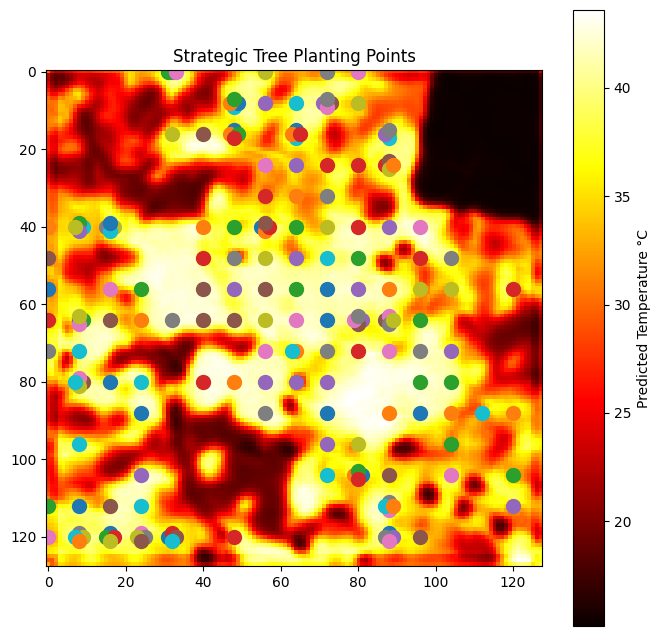

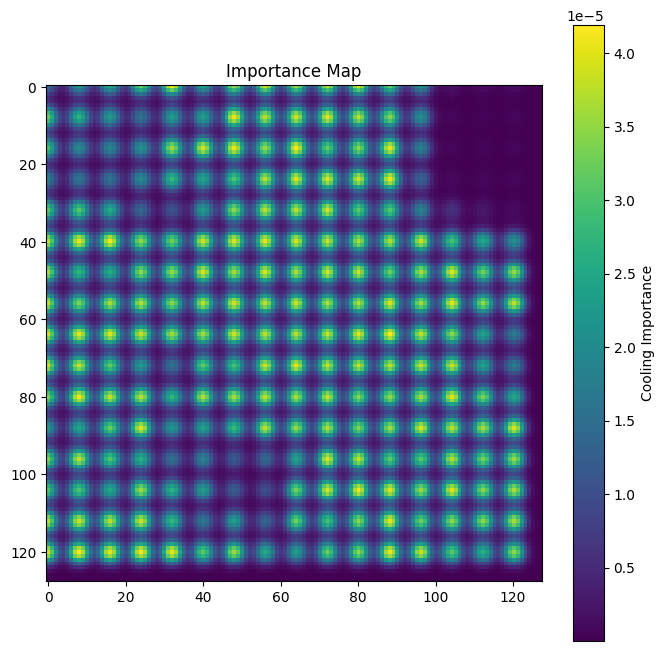

In [ ]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

from PIL import Image

IS_FREE_COLAB = True
FILES_DIR = "."

if IS_FREE_COLAB:
  from google.colab import drive
  drive.mount('/content/drive')
  FILES_DIR = "/content/drive/MyDrive/IA/Pibic/Vulnerability"


# ---------------- MODEL ----------------
class ThermalPredictor(nn.Module):
    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Conv3d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm3d(32),
            nn.ReLU(),

            nn.Conv3d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm3d(64),
            nn.ReLU(),

            nn.Conv3d(64, 3, kernel_size=3, padding=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        out = self.net(x)
        return out[:, :, -1, :, :]


# ---------------- NORMALIZATION ----------------
def normalize(arr):
    arr = arr.astype(np.float32).copy()

    arr[0] = (arr[0] + 1) / 2
    arr[1] = np.clip((arr[1] - 15) / 85, 0, 1)
    arr[2] = (arr[2] + 1) / 2

    return arr


def denormalize_temperature(temp):
    return temp * 85 + 15


# ---------------- LOAD INPUT ----------------
def load_sequence(files, img_size=(128, 128)):
    frames = []

    for f in files:
        arr = np.load(f)
        arr = normalize(arr)

        resized = []
        for c in range(arr.shape[0]):
            img = Image.fromarray(arr[c])
            img = img.resize(img_size, Image.BILINEAR)
            resized.append(np.array(img))

        arr = np.stack(resized)
        frames.append(arr)

    x = np.stack(frames, axis=1)  # [C,T,H,W]
    return torch.from_numpy(x).float().unsqueeze(0)


# ---------------- TREE SIMULATION ----------------
def simulate_tree(input_tensor, x, y, radius=4):
    """
    Simulate planting a tree:
    - increase NDVI
    - decrease NDBI
    """

    modified = input_tensor.clone()

    H = modified.shape[-2]
    W = modified.shape[-1]

    yy, xx = np.ogrid[:H, :W]
    mask = ((xx - x) ** 2 + (yy - y) ** 2) <= radius ** 2
    mask = torch.tensor(mask, dtype=torch.bool)

    last_frame = modified[0, :, -1]

    # NDVI up
    last_frame[0][mask] = torch.clamp(last_frame[0][mask] + 0.6, 0, 1)

    # NDBI down
    last_frame[2][mask] = torch.clamp(last_frame[2][mask] - 0.2, 0, 1)

    return modified


# ---------------- IMPORTANCE MAP ----------------
def compute_importance(model, input_tensor, step=8):
    model.eval()

    with torch.no_grad():
        baseline = model(input_tensor)[0, 1].cpu().numpy()

    H, W = baseline.shape
    importance = np.zeros((H, W))

    for y in range(0, H, step):
        for x in range(0, W, step):
            modified = simulate_tree(input_tensor, x, y)

            with torch.no_grad():
                pred = model(modified)[0, 1].cpu().numpy()

            cooling = baseline.mean() - pred.mean()
            importance[y, x] = cooling

            # print(f"Point ({x},{y}) -> {cooling:.6f}")

    importance = gaussian_filter(importance, sigma=2)
    return importance, baseline


# ---------------- TOP POINTS ----------------
def get_top_points(importance, k=10):
    flat = importance.flatten()
    indices = np.argpartition(flat, -k)[-k:]

    points = []
    W = importance.shape[1]

    for idx in indices:
        y = idx // W
        x = idx % W
        score = flat[idx]
        points.append((x, y, score))

    points.sort(key=lambda t: t[2], reverse=True)
    return points


# ---------------- VISUALIZATION ----------------
def visualize(baseline, importance, points):
    plt.figure(figsize=(8, 8))

    plt.imshow(denormalize_temperature(baseline), cmap="hot")
    plt.colorbar(label="Predicted Temperature °C")

    sum = 0

    for x, y, score in points:
        sum += score
        plt.scatter(x, y, s=100, marker="o")

    print(sum * 85)

    plt.title("Strategic Tree Planting Points")
    plt.show()

    plt.figure(figsize=(8, 8))
    plt.imshow(importance, cmap="viridis")
    plt.colorbar(label="Cooling Importance")
    plt.title("Importance Map")
    plt.show()


# ---------------- MAIN ----------------
if __name__ == "__main__":
    model = ThermalPredictor()
    model.load_state_dict(torch.load(f"{FILES_DIR}/best_thermal_model.pth", map_location="cpu"))
    model.eval()

    files = [
        f"{FILES_DIR}/landsat_dataset/Teresina_2024_01.npy",
        f"{FILES_DIR}/landsat_dataset/Teresina_2024_02.npy",
        f"{FILES_DIR}/landsat_dataset/Teresina_2024_03.npy",
        f"{FILES_DIR}/landsat_dataset/Teresina_2024_04.npy",
        f"{FILES_DIR}/landsat_dataset/Teresina_2024_05.npy",
        f"{FILES_DIR}/landsat_dataset/Teresina_2024_06.npy",
    ]

    x = load_sequence(files)

    importance, baseline = compute_importance(model, x, step=8)

    points = get_top_points(importance, k=200)

    # print("\nTop strategic points:")
    # for p in points:
    #     print(p)

    visualize(baseline, importance, points)

MAE: 2.8804 °C
RMSE: 3.6623 °C
Max Error: 26.4205 °C


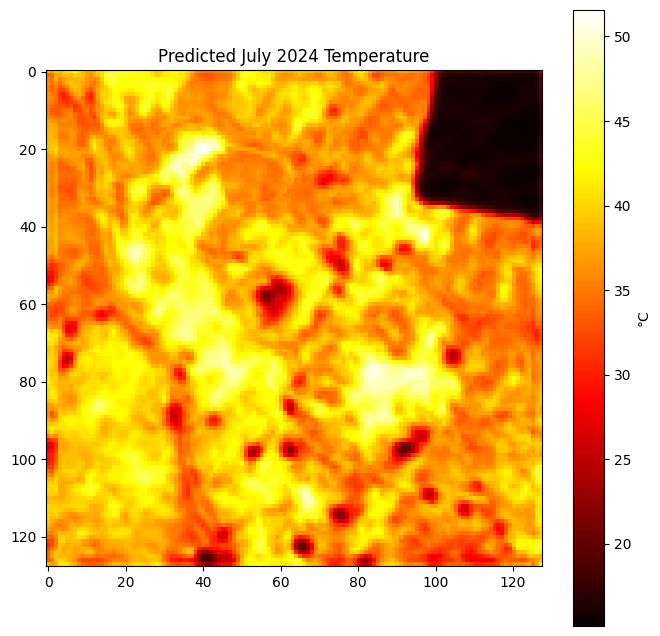

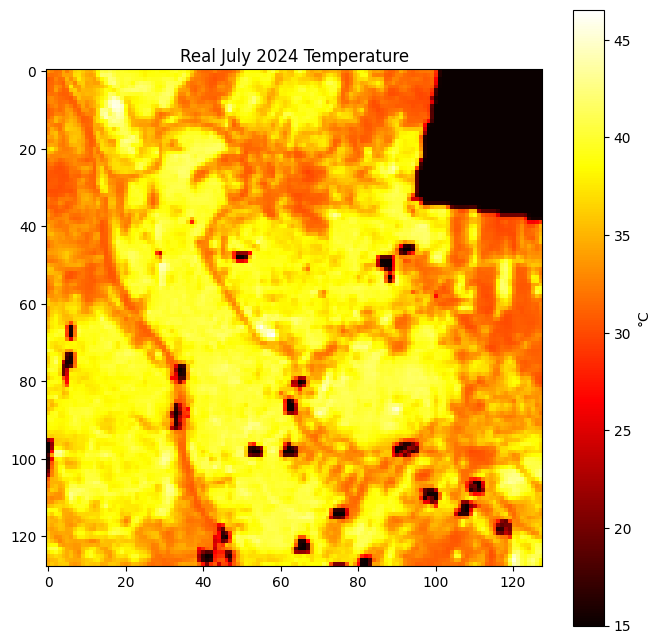

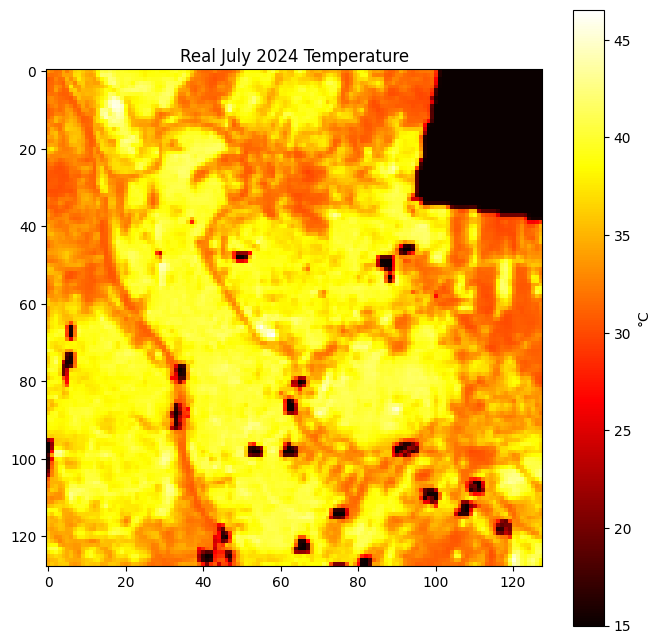

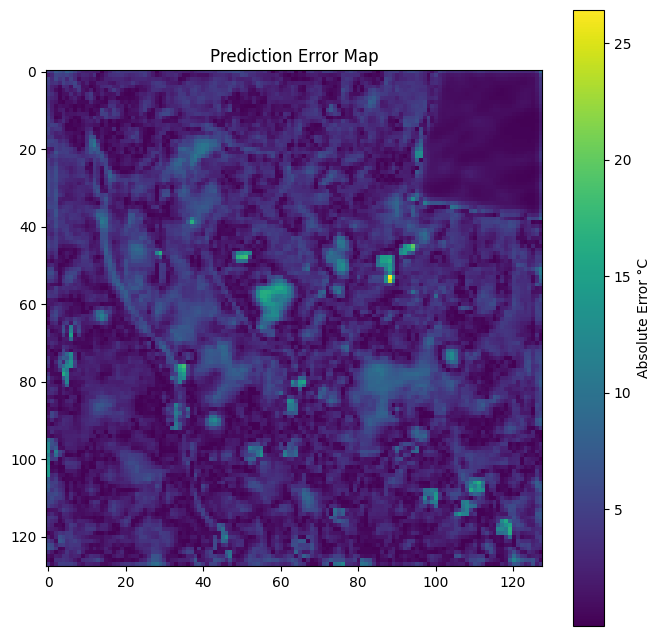

In [ ]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import mean_absolute_error, mean_squared_error

IS_FREE_COLAB = True
FILES_DIR = "."

if IS_FREE_COLAB:
  from google.colab import drive
  drive.mount('/content/drive')
  FILES_DIR = "/content/drive/MyDrive/IA/Pibic/Vulnerability"

# ---------------- MODEL ----------------
class ThermalPredictor(nn.Module):
    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Conv3d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm3d(32),
            nn.ReLU(),

            nn.Conv3d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm3d(64),
            nn.ReLU(),

            nn.Conv3d(64, 3, kernel_size=3, padding=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        out = self.net(x)
        return out[:, :, -1, :, :]


# ---------------- NORMALIZATION ----------------
def normalize(arr):
    arr = arr.astype(np.float32).copy()

    arr[0] = (arr[0] + 1) / 2
    arr[1] = np.clip((arr[1] - 15) / 85, 0, 1)
    arr[2] = (arr[2] + 1) / 2

    return arr


def denormalize_temperature(temp):
    return temp * 85 + 15


def resize(arr, img_size=(128, 128)):
    resized = []

    for c in range(arr.shape[0]):
        img = Image.fromarray(arr[c])
        img = img.resize(img_size, Image.BILINEAR)
        resized.append(np.array(img))

    return np.stack(resized)


# ---------------- LOAD SEQUENCE ----------------
def load_sequence(files):
    frames = []

    for f in files:
        arr = np.load(f)
        arr = normalize(arr)
        arr = resize(arr)
        frames.append(arr)

    x = np.stack(frames, axis=1)  # [C,T,H,W]
    return torch.from_numpy(x).float().unsqueeze(0)


def load_target(file):
    arr = np.load(file)
    arr = normalize(arr)
    arr = resize(arr)

    return arr


# ---------------- MAIN ----------------
if __name__ == "__main__":
    model = ThermalPredictor()
    model.load_state_dict(torch.load("best_thermal_model.pth", map_location="cpu"))
    model.eval()

    city = "Teresina"
    year = "2020"

    input_files = [
        f"{FILES_DIR}/landsat_dataset/{city}_{year}_01.npy",
        f"{FILES_DIR}/landsat_dataset/{city}_{year}_02.npy",
        f"{FILES_DIR}/landsat_dataset/{city}_{year}_03.npy",
        f"{FILES_DIR}/landsat_dataset/{city}_{year}_04.npy",
        f"{FILES_DIR}/landsat_dataset/{city}_{year}_05.npy",
        f"{FILES_DIR}/landsat_dataset/{city}_{year}_06.npy",
    ]

    x = str(int(year))
    target_file = f"{FILES_DIR}/landsat_dataset/{city}_{year}_07.npy"
    previous_file = f"{FILES_DIR}/landsat_dataset/{city}_{x}_07.npy"

    x = load_sequence(input_files)
    y_true = load_target(target_file)
    y_previous = load_target(previous_file)

    with torch.no_grad():
        pred = model(x)[0].numpy()

    # Use channel 1 = LST
    pred_temp = denormalize_temperature(pred[1])
    true_temp = denormalize_temperature(y_true[1])
    previous_temp = denormalize_temperature(y_previous[1])

    error_map = np.abs(pred_temp - true_temp)

    mae = mean_absolute_error(true_temp.flatten(), pred_temp.flatten())
    rmse = np.sqrt(mean_squared_error(true_temp.flatten(), pred_temp.flatten()))
    max_error = error_map.max()

    print(f"MAE: {mae:.4f} °C")
    print(f"RMSE: {rmse:.4f} °C")
    print(f"Max Error: {max_error:.4f} °C")

    # ---------------- PLOTS ----------------
    plt.figure(figsize=(8, 8))
    plt.imshow(pred_temp, cmap="hot")
    plt.colorbar(label="°C")
    plt.title("Predicted July 2024 Temperature")
    plt.show()

    plt.figure(figsize=(8, 8))
    plt.imshow(true_temp, cmap="hot")
    plt.colorbar(label="°C")
    plt.title("Real July 2024 Temperature")
    plt.show()

    plt.figure(figsize=(8, 8))
    plt.imshow(previous_temp, cmap="hot")
    plt.colorbar(label="°C")
    plt.title("Real July 2024 Temperature")
    plt.show()

    plt.figure(figsize=(8, 8))
    plt.imshow(error_map, cmap="viridis")
    plt.colorbar(label="Absolute Error °C")
    plt.title("Prediction Error Map")
    plt.show()

In [ ]:
import glob
import numpy as np

temps = []

for f in glob.glob("landsat_dataset/*.npy"):
    arr = np.load(f)

    lst = arr[1]  # temperature channel only
    temps.append(lst.flatten())

temps = np.concatenate(temps)

print("Temperature min:", np.nanmin(temps))
print("Temperature max:", np.nanmax(temps))
print("Temperature mean:", np.nanmean(temps))
print("NaN count:", np.isnan(temps).sum())

Temperature min: -30.868816179999982
Temperature max: 97.92901346000002
Temperature mean: 19.956200715918
NaN count: 0


In [ ]:
import shutil

# Parameters: (output_filename, format, source_dir)
# Note: output_filename should NOT include the .zip extension
shutil.make_archive('landsat_dataset2', 'zip', 'landsat_dataset')

print("Folder zipped successfully!")

KeyboardInterrupt: 

In [ ]:
import zipfile

zip_path = 'landsat_dataset.zip'
extract_to = 'landsat_dataset/'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to)

print(f"Files extracted to {extract_to}")

In [ ]:
import shutil
import os

folder_path = 'image_data'

# Check if the folder exists first to avoid errors
if os.path.exists(folder_path):
    shutil.rmtree(folder_path)
    print(f"Successfully deleted: {folder_path}")
else:
    print("The folder does not exist.")

Successfully deleted: data


In [ ]:
from google.colab import files

# 1. Create a dummy file (skip this if your file already exists)
filename = "landsat_dataset.zip"
with open(filename, "w") as f:
    f.write("This is the content of the file you are downloading.")

# 2. Trigger the browser download
files.download(filename)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Install the library
!pip install google-cloud-storage

# Authenticate Colab to your Google account
from google.colab import auth
auth.authenticate_user()

In [ ]:
import os
from google.cloud import storage

def upload_folder_to_gcs(bucket_name, local_folder_path, gcs_folder_name):
    """
    Uploads a local folder and its contents to a GCS bucket.
    """
    storage_client = storage.Client()
    bucket = storage_client.bucket(bucket_name)

    # Iterate through all files in the local directory
    for root, dirs, files in os.walk(local_folder_path):
        for file in files:
            # Create local file path
            local_path = os.path.join(root, file)

            # Create a relative path to maintain folder structure in GCS
            relative_path = os.path.relpath(local_path, local_folder_path)
            gcs_blob_path = os.path.join(gcs_folder_name, relative_path)

            # Upload the file
            blob = bucket.blob(gcs_blob_path)
            blob.upload_from_filename(local_path)
            print(f"Uploaded {local_path} to gs://{bucket_name}/{gcs_blob_path}")

# Example Usage:
upload_folder_to_gcs('pibic-questao-response', './landsat_dataset', 'landsat_dataset')

Uploaded ./landsat_dataset/Bom_Jesus_2021_03.npy to gs://pibic-questao-response/landsat_dataset/Bom_Jesus_2021_03.npy
Uploaded ./landsat_dataset/Campo_Maior_2019_09.npy to gs://pibic-questao-response/landsat_dataset/Campo_Maior_2019_09.npy
Uploaded ./landsat_dataset/Picos_2021_06.npy to gs://pibic-questao-response/landsat_dataset/Picos_2021_06.npy
Uploaded ./landsat_dataset/Sao_Raimundo_Nonato_2018_06.npy to gs://pibic-questao-response/landsat_dataset/Sao_Raimundo_Nonato_2018_06.npy
Uploaded ./landsat_dataset/Sao_Raimundo_Nonato_2023_09.npy to gs://pibic-questao-response/landsat_dataset/Sao_Raimundo_Nonato_2023_09.npy
Uploaded ./landsat_dataset/Piripiri_2019_05.npy to gs://pibic-questao-response/landsat_dataset/Piripiri_2019_05.npy
Uploaded ./landsat_dataset/Valenca_do_Piaui_2021_07.npy to gs://pibic-questao-response/landsat_dataset/Valenca_do_Piaui_2021_07.npy
Uploaded ./landsat_dataset/Urucui_2021_03.npy to gs://pibic-questao-response/landsat_dataset/Urucui_2021_03.npy
Uploaded ./lan

In [ ]:
from google.cloud import storage
from google.colab import auth

# 1. Authenticate (Only needed once per session)
auth.authenticate_user()

def download_from_gcs(bucket_name, source_blob_name, destination_file_name):
    """Downloads a blob from the bucket."""
    storage_client = storage.Client()
    bucket = storage_client.bucket(bucket_name)
    blob = bucket.blob(source_blob_name)

    # Download to the Colab local file system
    blob.download_to_filename(destination_file_name)

    print(f"File {source_blob_name} downloaded to {destination_file_name}.")

# Usage
download_from_gcs('landsat-dataset', '', 'downloaded_data.zip')

In [ ]:
!gsutil -m cp -r gs://pibic-questao-response/landsat_dataset/ ./

Google recommends using Gcloud storage CLI (https://docs.cloud.google.com/storage/docs/discover-object-storage-gcloud) instead of gsutil. Please refer to migration guide (https://docs.cloud.google.com/storage/docs/gsutil-transition-to-gcloud) for assistance.
Copying gs://pibic-questao-response/landsat_dataset/Altos_2018_02.npy...
Copying gs://pibic-questao-response/landsat_dataset/Altos_2018_01.npy...
Copying gs://pibic-questao-response/landsat_dataset/Altos_2018_03.npy...
Copying gs://pibic-questao-response/landsat_dataset/Altos_2018_04.npy...
Copying gs://pibic-questao-response/landsat_dataset/Altos_2018_06.npy...
Copying gs://pibic-questao-response/landsat_dataset/Altos_2018_09.npy...
Copying gs://pibic-questao-response/landsat_dataset/Altos_2018_05.npy...
Copying gs://pibic-questao-response/landsat_dataset/Altos_2018_10.npy...
Copying gs://pibic-questao-response/landsat_dataset/Altos_2018_07.npy...
Copying gs://pibic-questao-response/landsat_dataset/Altos_2018_08.npy...
Exception i

In [ ]:
!mkdir landsat_dataset

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


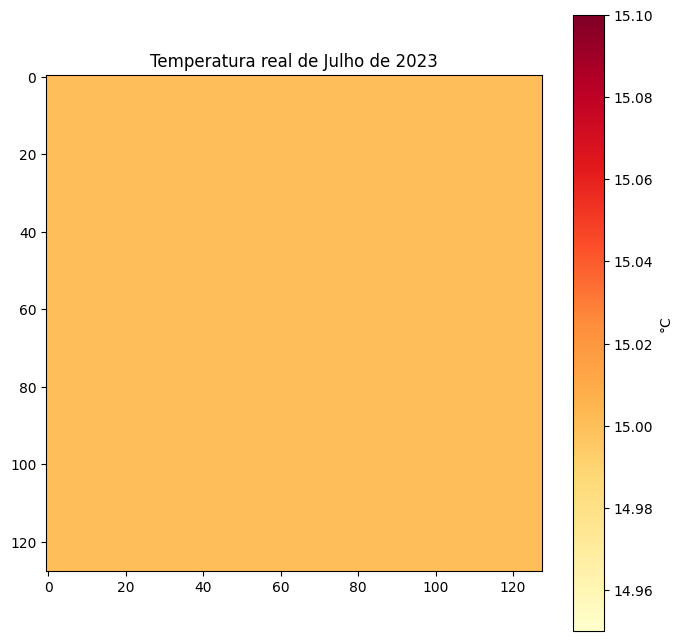

In [ ]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import mean_absolute_error, mean_squared_error

IS_FREE_COLAB = True
FILES_DIR = "."

if IS_FREE_COLAB:
  from google.colab import drive
  drive.mount('/content/drive')
  FILES_DIR = "/content/drive/MyDrive/IA/Pibic/Vulnerability"


# ---------------- NORMALIZATION ----------------
def normalize(arr):
    arr = arr.astype(np.float32).copy()

    arr[0] = (arr[0] + 1) / 2
    arr[1] = np.clip((arr[1] - 15) / 85, 0, 1)
    arr[2] = (arr[2] + 1) / 2

    return arr

def denormalize_temperature(temp):
    return temp * 85 + 15

def normalize_graphic(temp):
    # return np.max(temp) - temp
    return temp

def resize(arr, img_size=(128, 128)):
    resized = []

    for c in range(arr.shape[0]):
        img = Image.fromarray(arr[c])
        img = img.resize(img_size, Image.BILINEAR)
        resized.append(np.array(img))

    return np.stack(resized)


def load_target(file):
    arr = np.load(file)
    arr = normalize(arr)
    arr = resize(arr)

    return arr

city = "Pedro_II"
year = "2023"

target_file = f"{FILES_DIR}/landsat_dataset/{city}_{year}_03.npy"

y_true = load_target(target_file)

# Use channel 1 = LST
true_temp = denormalize_temperature(y_true[1])

v_min = 14.95
v_max = 15.1

# true_temp[true_temp < v_min] = v_min
# true_temp[true_temp > v_max] = v_max

plt.figure(figsize=(8, 8))
plt.imshow(normalize_graphic(true_temp), cmap="YlOrRd", vmin=v_min, vmax=v_max)
plt.colorbar(label="°C")
plt.title(f"Temperatura real de Julho de {year}")
plt.show()

In [ ]:
!pip install ee geemap

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.4/65.4 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 61.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 479.3/479.3 kB 35.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 113.4/113.4 kB 10.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.5/58.5 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 935.4/935.4 kB 59.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.6/98.6 kB 10.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.4/102.4 kB 10.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 96.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 516.3/516.3 kB 9.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.2/15.2 MB 80.5 MB/s eta

In [ ]:
#SAVE THE DATASET

import ee
import geemap
import numpy as np
import os

IS_FREE_COLAB = False
FILES_DIR = "."

if IS_FREE_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    FILES_DIR = "/content/drive/MyDrive/IA/Pibic/Vulnerability"

ee.Authenticate()
ee.Initialize(project="script-39a43")


cidades = {
    "Teresina": [-42.86, -5.16, -42.70, -5.00],
    "Parnaiba": [-41.85, -3.00, -41.68, -2.85],
    "Picos": [-41.52, -7.15, -41.40, -7.00],
    "Floriano": [-43.05, -6.85, -42.95, -6.72],
    "Piripiri": [-41.83, -4.35, -41.72, -4.22],
    "Campo_Maior": [-42.20, -4.90, -42.08, -4.78],
    "Barras": [-42.33, -4.25, -42.18, -4.12],
    "Bom_Jesus": [-44.45, -9.15, -44.30, -9.00],
    "Oeiras": [-42.15, -7.05, -42.00, -6.92],
    "Sao_Raimundo_Nonato": [-42.78, -9.05, -42.63, -8.90],
    "Esperantina": [-42.25, -3.92, -42.10, -3.78],
    "Pedro_II": [-41.50, -4.48, -41.35, -4.35],
    "Corrente": [-45.20, -10.52, -45.05, -10.35],
    "Urucui": [-44.55, -7.30, -44.35, -7.10],
    "Valenca_do_Piaui": [-41.80, -6.48, -41.62, -6.30],
    "Paulistana": [-41.10, -8.18, -40.92, -8.00],
    "Canto_do_Buriti": [-42.98, -8.08, -42.80, -7.90],
    "Altos": [-42.48, -5.08, -42.32, -4.92],
    "Jose_de_Freitas": [-42.62, -4.82, -42.45, -4.65],
    "Luzilandia": [-42.35, -3.55, -42.18, -3.40],
}


def mask_landsat_clouds(image):
    qa = image.select("QA_PIXEL")

    cloud_shadow_bit = 1 << 4
    clouds_bit = 1 << 3

    mask = (
        qa.bitwiseAnd(cloud_shadow_bit).eq(0)
        .And(qa.bitwiseAnd(clouds_bit).eq(0))
    )

    return image.updateMask(mask)


def scale_sr_band(img, band_name):
    return (
        img.select(band_name)
        .multiply(0.0000275)
        .add(-0.2)
        .rename(band_name.replace("SR_", ""))
    )


def process_image(img, roi, month):
    img = img.clip(roi)

    # Scaled reflectance bands
    b2 = scale_sr_band(img, "SR_B2")
    b3 = scale_sr_band(img, "SR_B3")
    b4 = scale_sr_band(img, "SR_B4")
    b5 = scale_sr_band(img, "SR_B5")
    b6 = scale_sr_band(img, "SR_B6")

    # Indices
    ndvi = b5.subtract(b4).divide(b5.add(b4)).rename("NDVI")
    ndbi = b6.subtract(b5).divide(b6.add(b5)).rename("NDBI")

    # Land Surface Temperature (Celsius)
    lst = (
        img.select("ST_B10")
        .multiply(0.00341802)
        .add(149.0)
        .subtract(273.15)
        .rename("LST")
    )

    # Month cyclical encoding
    month_sin_value = np.sin(2 * np.pi * month / 12)
    month_cos_value = np.cos(2 * np.pi * month / 12)

    month_sin = ee.Image.constant(month_sin_value).rename("month_sin")
    month_cos = ee.Image.constant(month_cos_value).rename("month_cos")

    combined = ee.Image.cat([
        lst,
        ndvi,
        ndbi,
        b2, b3, b4, b5, b6,
        month_sin,
        month_cos
    ])

    return combined


def download_landsat_dataset(start_year, end_year, folder):
    os.makedirs(folder, exist_ok=True)

    base_collection = (
        ee.ImageCollection("LANDSAT/LC08/C02/T1_L2")
        .filter(ee.Filter.lt("CLOUD_COVER", 20))
        .map(mask_landsat_clouds)
    )

    for city_name, coords in cidades.items():
        roi = ee.Geometry.Rectangle(coords)

        for year in range(start_year, end_year + 1):
            for month in range(1, 13):
                start = f"{year}-{month:02d}-01"

                if month == 12:
                    end = f"{year+1}-01-01"
                else:
                    end = f"{year}-{month+1:02d}-01"

                collection = (
                    base_collection
                    .filterBounds(roi)
                    .filterDate(start, end)
                )

                size = collection.size().getInfo()
                if size == 0:
                    print(f"Skipping {city_name} {year}-{month:02d} (no images)")
                    continue

                img = collection.median()
                combined = process_image(img, roi, month)

                try:
                    array = geemap.ee_to_numpy(
                        combined,
                        region=roi,
                        scale=30
                    )

                    if array is None:
                        print(f"Skipping {city_name} {year}-{month:02d} (empty array)")
                        continue

                    # Convert [H,W,C] -> [C,H,W]
                    array = np.transpose(array, (2, 0, 1)).astype(np.float32)

                    filename = f"{city_name}_{year}_{month:02d}.npy"
                    path = os.path.join(folder, filename)

                    np.save(path, array)

                    print(f"Saved {filename} shape={array.shape}")

                except Exception as e:
                    print(f"Error {city_name} {year}-{month:02d}: {e}")


download_landsat_dataset(
    start_year=2018,
    end_year=2024,
    folder=f"{FILES_DIR}/landsat_dataset"
)

Skipping Teresina 2018-01 (no images)
Skipping Teresina 2018-02 (no images)
Skipping Teresina 2018-03 (no images)
Saved Teresina_2018_04.npy shape=(10, 594, 595)
Saved Teresina_2018_05.npy shape=(10, 594, 595)
Saved Teresina_2018_06.npy shape=(10, 594, 595)
Saved Teresina_2018_07.npy shape=(10, 594, 595)
Saved Teresina_2018_08.npy shape=(10, 594, 595)
Saved Teresina_2018_09.npy shape=(10, 594, 595)
Saved Teresina_2018_10.npy shape=(10, 594, 595)
Saved Teresina_2018_11.npy shape=(10, 594, 595)
Saved Teresina_2018_12.npy shape=(10, 594, 595)
Skipping Teresina 2019-01 (no images)
Skipping Teresina 2019-02 (no images)
Saved Teresina_2019_03.npy shape=(10, 594, 595)
Skipping Teresina 2019-04 (no images)
Saved Teresina_2019_05.npy shape=(10, 594, 595)
Saved Teresina_2019_06.npy shape=(10, 594, 595)
Saved Teresina_2019_07.npy shape=(10, 594, 595)
Saved Teresina_2019_08.npy shape=(10, 594, 595)
Saved Teresina_2019_09.npy shape=(10, 594, 595)
Skipping Teresina 2019-10 (no images)
Saved Teresina

In [ ]:
#TRAIN THE MODEL

import os
import glob
import numpy as np
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader


IS_FREE_COLAB = False
FILES_DIR = "."

if IS_FREE_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    FILES_DIR = "/content/drive/MyDrive/IA/Pibic/Vulnerability"


class ConvLSTMCell(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super().__init__()

        self.hidden_dim = hidden_dim

        self.conv = nn.Conv2d(
            input_dim + hidden_dim,
            hidden_dim * 4,
            kernel_size=3,
            padding=1
        )

    def forward(self, x, h, c):
        combined = torch.cat([x, h], dim=1)
        gates = self.conv(combined)

        i, f, o, g = torch.chunk(gates, 4, dim=1)

        i = torch.sigmoid(i)
        f = torch.sigmoid(f)
        o = torch.sigmoid(o)
        g = torch.tanh(g)

        c = f * c + i * g
        h = o * torch.tanh(c)

        return h, c

    def init_hidden(self, batch, h, w, device):
        return (
            torch.zeros(batch, self.hidden_dim, h, w, device=device),
            torch.zeros(batch, self.hidden_dim, h, w, device=device)
        )


class ThermalPredictor(nn.Module):
    def __init__(self):
        super().__init__()

        self.lstm1 = ConvLSTMCell(10, 32)
        self.lstm2 = ConvLSTMCell(32, 64)

        self.head = nn.Sequential(
            nn.Conv2d(64, 32, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 1, 1)
        )

    def forward(self, x):
        B, C, T, H, W = x.shape
        device = x.device

        h1, c1 = self.lstm1.init_hidden(B, H, W, device)
        h2, c2 = self.lstm2.init_hidden(B, H, W, device)

        for t in range(T):
            x_t = x[:, :, t]

            h1, c1 = self.lstm1(x_t, h1, c1)
            h2, c2 = self.lstm2(h1, h2, c2)

        delta = self.head(h2)

        last_lst = x[:, 0:1, -1]
        pred = last_lst + delta

        pred = torch.clamp(pred, 0, 1)
        return pred


class LandsatDataset(Dataset):
    def __init__(self, folder, seq_len=6, img_size=(128, 128), years=None):
        self.samples = []
        self.seq_len = seq_len
        self.img_size = img_size

        files = sorted(glob.glob(os.path.join(folder, "*.npy")))

        by_city = {}

        for f in files:
            name = os.path.basename(f)
            city = "_".join(name.split("_")[:-2])
            year = int(name.split("_")[-2])

            if years is not None and year not in years:
                continue

            by_city.setdefault(city, []).append(f)

        for city_files in by_city.values():
            city_files = sorted(city_files)

            for i in range(len(city_files) - seq_len):
                self.samples.append(
                    (city_files[i:i+seq_len], city_files[i+seq_len])
                )

    def normalize(self, arr):
        arr = arr.astype(np.float32)

        arr[0] = np.clip((arr[0] - 15) / 40, 0, 1)
        arr[1] = (arr[1] + 1) / 2
        arr[2] = (arr[2] + 1) / 2

        for i in range(3, 8):
            arr[i] = np.clip((arr[i] + 0.2) / 1.2, 0, 1)

        arr[8] = (arr[8] + 1) / 2
        arr[9] = (arr[9] + 1) / 2

        return arr

    def resize(self, arr):
        resized = []

        for c in range(arr.shape[0]):
            img = Image.fromarray(arr[c])
            img = img.resize(self.img_size, Image.BILINEAR)
            resized.append(np.array(img))

        return np.stack(resized)

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        input_files, target_file = self.samples[idx]

        frames = []

        for f in input_files:
            arr = self.resize(self.normalize(np.load(f)))
            frames.append(arr)

        x = np.stack(frames, axis=1)

        y = self.resize(self.normalize(np.load(target_file)))[0:1]

        return (
            torch.from_numpy(x).float(),
            torch.from_numpy(y).float()
        )


def train():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    train_ds = LandsatDataset(
        f"{FILES_DIR}/landsat_dataset",
        years=[2018, 2019, 2020, 2021, 2022]
    )

    val_ds = LandsatDataset(
        f"{FILES_DIR}/landsat_dataset",
        years=[2023, 2024]
    )

    train_loader = DataLoader(train_ds, batch_size=8, shuffle=True, num_workers=2)
    val_loader = DataLoader(val_ds, batch_size=8, num_workers=2)

    model = ThermalPredictor().to(device)

    optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        patience=5,
        factor=0.5
    )

    l1 = nn.L1Loss()
    mse = nn.MSELoss()

    best = 999

    for epoch in range(50):
        model.train()
        train_loss = 0

        for x, y in train_loader:
            x, y = x.to(device), y.to(device)

            pred = model(x)
            loss = l1(pred, y) + 0.5 * mse(pred, y)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            train_loss += loss.item()

        model.eval()
        val_loss = 0

        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)

                pred = model(x)
                loss = l1(pred, y) + 0.5 * mse(pred, y)
                val_loss += loss.item()

        train_loss /= len(train_loader)
        val_loss /= len(val_loader)

        scheduler.step(val_loss)

        print(
            f"Epoch {epoch:03d} | "
            f"Train {train_loss:.4f} | "
            f"Val {val_loss:.4f}"
        )

        if val_loss < best:
            best = val_loss
            torch.save(model.state_dict(), "best_thermal_model.pth")
            print("Saved best model")


train()

Epoch 000 | Train 0.2120 | Val 0.1861
Saved best model
Epoch 001 | Train 0.1978 | Val 0.1872
Epoch 002 | Train 0.1926 | Val 0.1800
Saved best model
Epoch 003 | Train 0.1873 | Val 0.1777
Saved best model
Epoch 004 | Train 0.1826 | Val 0.1710
Saved best model
Epoch 005 | Train 0.1803 | Val 0.1635
Saved best model
Epoch 006 | Train 0.1696 | Val 0.1523
Saved best model
Epoch 007 | Train 0.1622 | Val 0.1532
Epoch 008 | Train 0.1587 | Val 0.1527
Epoch 009 | Train 0.1546 | Val 0.1501
Saved best model
Epoch 010 | Train 0.1530 | Val 0.1577
Epoch 011 | Train 0.1517 | Val 0.1348
Saved best model
Epoch 012 | Train 0.1494 | Val 0.1437
Epoch 013 | Train 0.1500 | Val 0.1332
Saved best model
Epoch 014 | Train 0.1515 | Val 0.1525
Epoch 015 | Train 0.1485 | Val 0.1371
Epoch 016 | Train 0.1461 | Val 0.1354
Epoch 017 | Train 0.1467 | Val 0.1396
Epoch 018 | Train 0.1470 | Val 0.1355
Epoch 019 | Train 0.1455 | Val 0.1427
Epoch 020 | Train 0.1427 | Val 0.1373
Epoch 021 | Train 0.1427 | Val 0.1413
Epoch 022 |

KeyboardInterrupt: 

MAE: 1.1035 °C
RMSE: 1.6890 °C
Max Error: 22.0567 °C


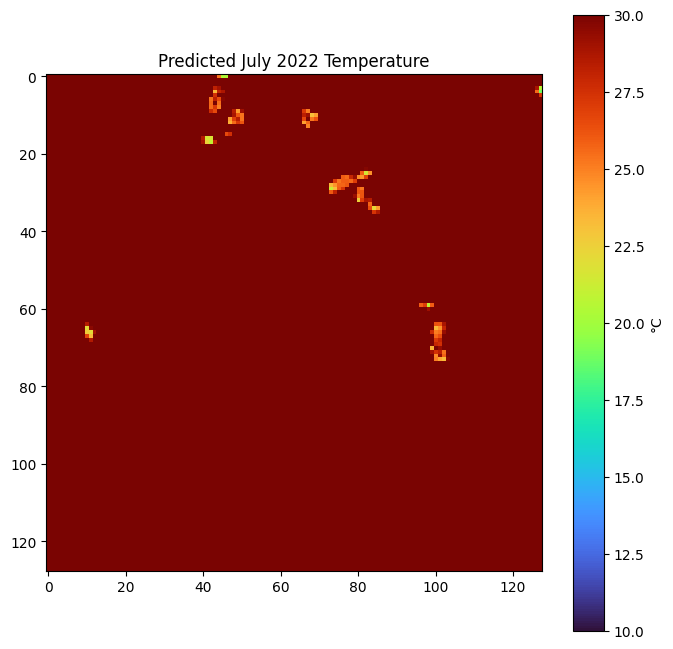

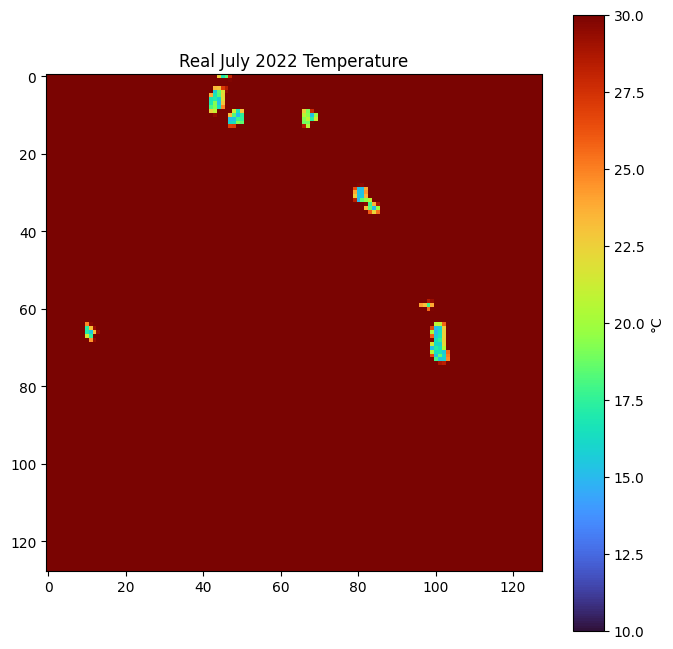

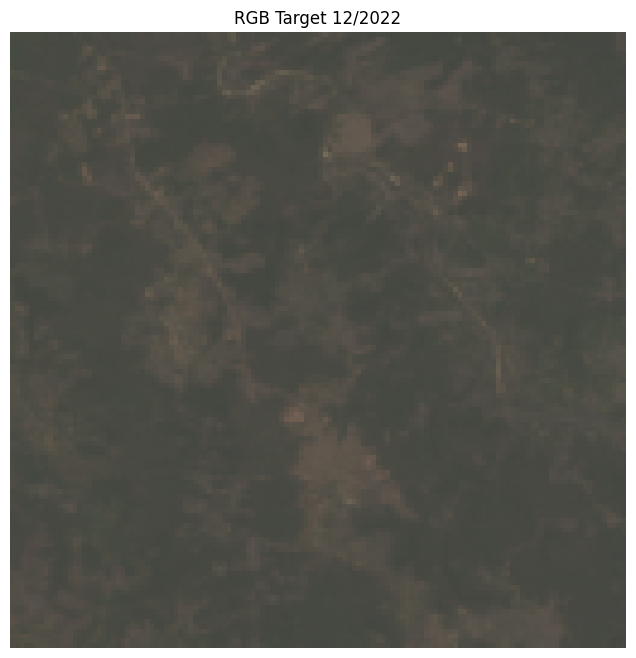

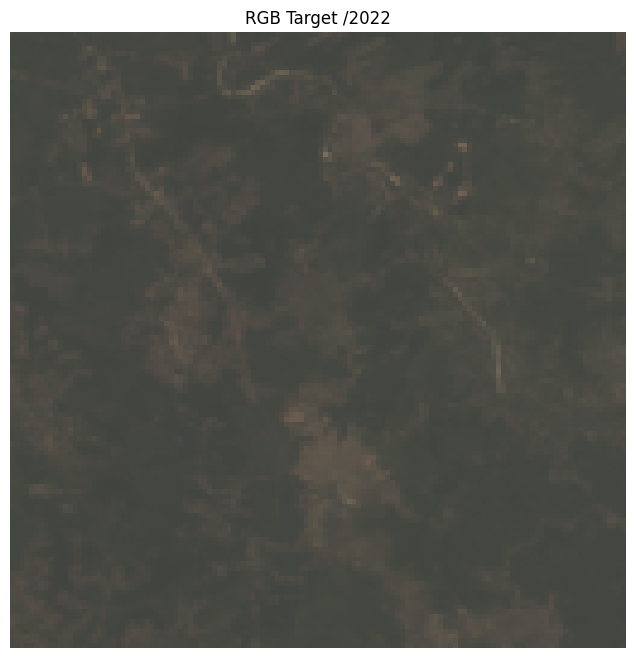

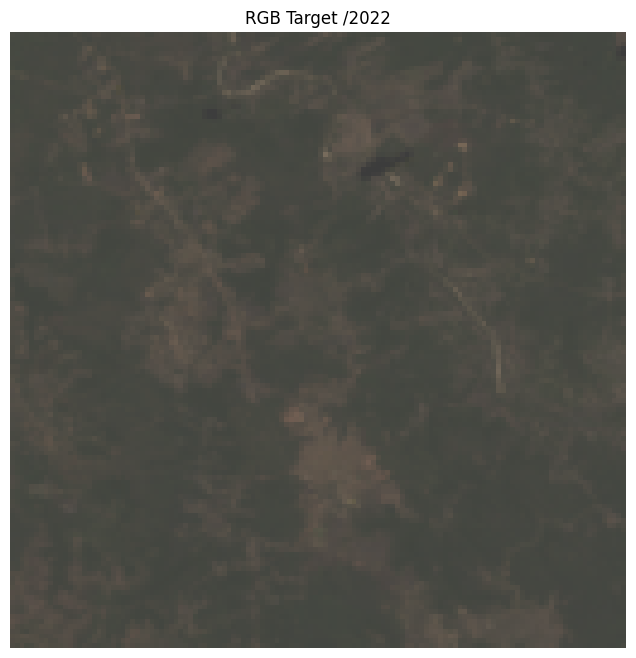

In [ ]:
# GET THE CITY DATA AND PREDICT
# 1021 files with multispectral
# Epoch 006 | Train 0.1664 | Val 0.1776

import ee
import geemap
import numpy as np
import os
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import mean_absolute_error, mean_squared_error

IS_FREE_COLAB = False
FILES_DIR = "."
TEMP_DIR = "./temp_dir"

if IS_FREE_COLAB:
  from google.colab import drive
  drive.mount('/content/drive')
  FILES_DIR = "/content/drive/MyDrive/IA/Pibic/Vulnerability"

ee.Authenticate()
ee.Initialize(project="script-39a43")

def get_dates(year, month):
  year = int(year)

  dates = []

  # for i in range(12):
  #   dates += [(year - 1, i + 1)]

  for i in range(12 - month):
    dates += [(year - 1, month + i + 1)]

  for i in range(month):
    dates += [(year, i + 1)]

  return dates

def get_geometry(city):
  cities = ee.FeatureCollection("FAO/GAUL/2015/level2")

  city_infos = cities.filter(
      ee.Filter.And(
          ee.Filter.eq('ADM0_NAME', 'Brazil'),
          ee.Filter.eq('ADM2_NAME', city)
      )
  )

  if not city_infos:
    print(f"Cidade {city} não encontrada. Tente novamente.")
    return None

  # Get geometry
  geom = city_infos.geometry()



  points = geom.bounds().getInfo()['coordinates'][0]

  lons = [p[0] for p in points]
  lats = [p[1] for p in points]

  coords = [
      min(lons),  # west
      min(lats),  # south
      max(lons),  # east
      max(lats)   # north
  ]


  return coords

def mask_landsat_clouds(image):
    qa = image.select("QA_PIXEL")

    cloud_shadow_bit = 1 << 4
    clouds_bit = 1 << 3

    mask = (
        qa.bitwiseAnd(cloud_shadow_bit).eq(0)
        .And(qa.bitwiseAnd(clouds_bit).eq(0))
    )

    return image.updateMask(mask)


def scale_sr_band(img, band_name):
    return (
        img.select(band_name)
        .multiply(0.0000275)
        .add(-0.2)
        .rename(band_name.replace("SR_", ""))
    )


def process_image(img, roi, month):
    img = img.clip(roi)

    # Scaled reflectance bands
    b2 = scale_sr_band(img, "SR_B2")
    b3 = scale_sr_band(img, "SR_B3")
    b4 = scale_sr_band(img, "SR_B4")
    b5 = scale_sr_band(img, "SR_B5")
    b6 = scale_sr_band(img, "SR_B6")

    # Indices
    ndvi = b5.subtract(b4).divide(b5.add(b4)).rename("NDVI")
    ndbi = b6.subtract(b5).divide(b6.add(b5)).rename("NDBI")

    # Land Surface Temperature (Celsius)
    lst = (
        img.select("ST_B10")
        .multiply(0.00341802)
        .add(149.0)
        .subtract(273.15)
        .rename("LST")
    )

    # Month cyclical encoding
    month_sin_value = np.sin(2 * np.pi * month / 12)
    month_cos_value = np.cos(2 * np.pi * month / 12)

    month_sin = ee.Image.constant(month_sin_value).rename("month_sin")
    month_cos = ee.Image.constant(month_cos_value).rename("month_cos")

    combined = ee.Image.cat([
        lst,
        ndvi,
        ndbi,
        b2, b3, b4, b5, b6,
        month_sin,
        month_cos
    ])

    return combined

def download_landsat_dataset(dates, folder, coords, city_name):
    os.makedirs(folder, exist_ok=True)

    base_collection = (
        ee.ImageCollection("LANDSAT/LC08/C02/T1_L2")
        .filter(ee.Filter.lt("CLOUD_COVER", 20))
        .map(mask_landsat_clouds)
    )

    roi = ee.Geometry.Rectangle(coords)

    for year, month in dates:
        start = f"{year}-{month:02d}-01"

        if month == 12:
            end = f"{year+1}-01-01"
        else:
            end = f"{year}-{month+1:02d}-01"

        collection = base_collection.filterDate(start, end)

        size = collection.size().getInfo()
        if size == 0:
            print(f"Skipping {city_name} {year}-{month:02d} (no images)")
            continue

        img = collection.median()
        combined = process_image(img, roi, month)

        try:
            array = geemap.ee_to_numpy(
                combined,
                region=roi,
                scale=30
            )

            if array is None:
                continue

            array = np.transpose(array, (2, 0, 1))  # [C,H,W]

            filename = f"{city_name}_{year}_{month:02d}.npy"
            np.save(os.path.join(folder, filename), array)

            print(f"Saved {filename} shape={array.shape}")

        except Exception as e:
            print(f"Error {city_name} {year}-{month:02d}: {e}")

# ---------------- CONVLSTM ----------------
class ConvLSTMCell(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super().__init__()

        self.hidden_dim = hidden_dim

        self.conv = nn.Conv2d(
            input_dim + hidden_dim,
            hidden_dim * 4,
            kernel_size=3,
            padding=1
        )

    def forward(self, x, h, c):
        combined = torch.cat([x, h], dim=1)
        gates = self.conv(combined)

        i, f, o, g = torch.chunk(gates, 4, dim=1)

        i = torch.sigmoid(i)
        f = torch.sigmoid(f)
        o = torch.sigmoid(o)
        g = torch.tanh(g)

        c = f * c + i * g
        h = o * torch.tanh(c)

        return h, c

    def init_hidden(self, batch, h, w, device):
        return (
            torch.zeros(batch, self.hidden_dim, h, w, device=device),
            torch.zeros(batch, self.hidden_dim, h, w, device=device)
        )


class ThermalPredictor(nn.Module):
    def __init__(self):
        super().__init__()

        self.lstm1 = ConvLSTMCell(10, 32)
        self.lstm2 = ConvLSTMCell(32, 64)

        self.head = nn.Sequential(
            nn.Conv2d(64, 32, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 1, 1)
        )

    def forward(self, x):
        B, C, T, H, W = x.shape
        device = x.device

        h1, c1 = self.lstm1.init_hidden(B, H, W, device)
        h2, c2 = self.lstm2.init_hidden(B, H, W, device)

        for t in range(T):
            x_t = x[:, :, t]
            h1, c1 = self.lstm1(x_t, h1, c1)
            h2, c2 = self.lstm2(h1, h2, c2)

        delta = self.head(h2)

        last_lst = x[:, 0:1, -1]
        pred = last_lst + delta
        pred = torch.clamp(pred, 0, 1)

        return pred


# ---------------- PREPROCESS ----------------
def normalize(arr):
    arr = arr.astype(np.float32).copy()

    arr[0] = np.clip((arr[0] - 15) / 40, 0, 1)
    arr[1] = (arr[1] + 1) / 2
    arr[2] = (arr[2] + 1) / 2

    for i in range(3, 8):
        arr[i] = np.clip((arr[i] + 0.2) / 1.2, 0, 1)

    arr[8] = (arr[8] + 1) / 2
    arr[9] = (arr[9] + 1) / 2

    return arr


def denormalize_temperature(temp):
    return temp * 40 + 15


def resize(arr, img_size=(128, 128)):
    resized = []

    for c in range(arr.shape[0]):
        img = Image.fromarray(arr[c])
        img = img.resize(img_size, Image.BILINEAR)
        resized.append(np.array(img))

    return np.stack(resized)


def load_sequence(files):
    frames = []

    for f in files:
        arr = np.load(f)
        arr = normalize(arr)
        arr = resize(arr)
        frames.append(arr)

    x = np.stack(frames, axis=1)  # [C,T,H,W]
    return torch.from_numpy(x).float().unsqueeze(0)


def load_target(file):
    arr = np.load(file)
    arr = normalize(arr)
    arr = resize(arr)
    return arr


def get_rgb_image(arr):
    # channels:
    # 3=B2
    # 4=B3
    # 5=B4

    blue = arr[3]
    green = arr[4]
    red = arr[5]

    rgb = np.stack([red, green, blue], axis=-1)
    rgb = np.clip(rgb, 0, 1)
    rgb = rgb ** 0.8

    return rgb

city = "Demerval Lobao"
year = "2022"
month = 11

# dates = get_dates(year, month)


# download_landsat_dataset(
#     dates = [(2021,12)],
#     folder=f"./temp_dir",
#     coords=get_geometry(city),
#     city_name=city
# )

# download_landsat_dataset(
#     dates = [("2023", 2)],
#     folder=f"./temp_dir",
#     coords=get_geometry(city),
#     city_name=city
# )


model = ThermalPredictor()
model.load_state_dict(torch.load(f"{FILES_DIR}/best_thermal_model.pth", map_location="cpu"))
model.eval()

# input_files = [
#     f"{FILES_DIR}/temp_dir/{city}_{year}_{month:02d}.npy" for year, month in dates]

input_files = [
    f"{FILES_DIR}/temp_dir/{city}_{int(year)}_08.npy",
    f"{FILES_DIR}/temp_dir/{city}_{int(year)}_09.npy",
    # f"{FILES_DIR}/temp_dir/{city}_{int(year)}_10.npy",
    # f"{FILES_DIR}/temp_dir/{city}_{int(year)}_11.npy",
    # f"{FILES_DIR}/landsat_dataset/{city}_{year}_05.npy",
    # f"{FILES_DIR}/landsat_dataset/{city}_{year}_06.npy",
    #  f"{FILES_DIR}/landsat_dataset/{city}_{year}_07.npy",
    # f"{FILES_DIR}/landsat_dataset/{city}_{year}_08.npy",
    # f"{FILES_DIR}/landsat_dataset/{city}_{year}_09.npy",
    # f"{FILES_DIR}/landsat_dataset/{city}_{year}_10.npy"
]

# input_files = [
#     f"{FILES_DIR}/landsat_dataset/{city}_{int(year)-1}_07.npy",
#     f"{FILES_DIR}/landsat_dataset/{city}_{int(year)-1}_08.npy",
#     f"{FILES_DIR}/landsat_dataset/{city}_{int(year)-1}_09.npy",
#     f"{FILES_DIR}/landsat_dataset/{city}_{int(year)-1}_10.npy",
# input_files = [
#     f"{FILES_DIR}/landsat_dataset/{city}_{int(year)-1}_07.npy",
#     f"{FILES_DIR}/landsat_dataset/{city}_{int(year)-1}_08.npy",
#     f"{FILES_DIR}/landsat_dataset/{city}_{int(year)-1}_09.npy",
#     f"{FILES_DIR}/landsat_dataset/{city}_{int(year)-1}_10.npy",
#     f"{FILES_DIR}/landsat_dataset/{city}_{year}_05.npy",
#     f"{FILES_DIR}/landsat_dataset/{city}_{year}_06.npy",
#      f"{FILES_DIR}/landsat_dataset/{city}_{year}_07.npy",
#     f"{FILES_DIR}/landsat_dataset/{city}_{year}_08.npy",
#     f"{FILES_DIR}/landsat_dataset/{city}_{year}_09.npy",
#     # f"{FILES_DIR}/landsat_dataset/{city}_{year}_10.npy"
# ]

# target_file = f"{FILES_DIR}/landsat_dataset/{city}_{2023}_{10:02d}.npy"
target_file = f"{FILES_DIR}/temp_dir/{city}_{year}_{10:02d}.npy"

x = load_sequence(input_files)
y_true = load_target(target_file)

with torch.no_grad():
    pred = model(x)[0].numpy()

# Use channel 1 = LST
pred_temp = denormalize_temperature(pred[0])
true_temp = denormalize_temperature(y_true[0])
rgb_temp = get_rgb_image(y_true)

error_map = np.abs(pred_temp - true_temp)

mae = mean_absolute_error(true_temp.flatten(), pred_temp.flatten())
rmse = np.sqrt(mean_squared_error(true_temp.flatten(), pred_temp.flatten()))
max_error = error_map.max()

print(f"MAE: {mae:.4f} °C")
print(f"RMSE: {rmse:.4f} °C")
print(f"Max Error: {max_error:.4f} °C")

v_min = 10
v_max = 30

# ---------------- PLOTS ----------------
plt.figure(figsize=(8, 8))
plt.imshow(pred_temp, cmap="turbo", vmin=v_min, vmax=v_max)
plt.colorbar(label="°C")
plt.title(f"Predicted July {year} Temperature")
plt.show()

plt.figure(figsize=(8, 8))
plt.imshow(true_temp, cmap="turbo", vmin=v_min, vmax=v_max)
plt.colorbar(label="°C")
plt.title(f"Real July {year} Temperature")
plt.show()

plt.figure(figsize=(8, 8))
plt.imshow(rgb_temp)
plt.title(f"RGB Target {month+1:02d}/{year}")
plt.axis("off")
plt.show()


for item in input_files:
  i = load_target(item)
  pred = get_rgb_image(i)

  plt.figure(figsize=(8, 8))
  plt.imshow(pred)
  plt.title(f"RGB Target /{year}")
  plt.axis("off")
  plt.show()
# import shutil

# shutil.rmtree("temp_dir")

In [ ]:
import ee
import geemap
import numpy as np
import os
import json

# ============================================================
# CONFIG
# ============================================================

IS_FREE_COLAB = False
FILES_DIR = "."

if IS_FREE_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    FILES_DIR = "/content/drive/MyDrive/IA/Pibic/Vulnerability"

ee.Authenticate()
ee.Initialize(project="script-39a43")

# ============================================================
# CIDADES
# ============================================================

cidades = {
    "Teresina": [-42.86, -5.16, -42.70, -5.00],
    "Parnaiba": [-41.85, -3.00, -41.68, -2.85],
    "Picos": [-41.52, -7.15, -41.40, -7.00],
    "Floriano": [-43.05, -6.85, -42.95, -6.72],
    "Piripiri": [-41.83, -4.35, -41.72, -4.22],
    "Campo_Maior": [-42.20, -4.90, -42.08, -4.78],
    "Barras": [-42.33, -4.25, -42.18, -4.12],
    "Bom_Jesus": [-44.45, -9.15, -44.30, -9.00],
    "Oeiras": [-42.15, -7.05, -42.00, -6.92],
    "Sao_Raimundo_Nonato": [-42.78, -9.05, -42.63, -8.90],
    "Esperantina": [-42.25, -3.92, -42.10, -3.78],
    "Pedro_II": [-41.50, -4.48, -41.35, -4.35],
    "Corrente": [-45.20, -10.52, -45.05, -10.35],
    "Urucui": [-44.55, -7.30, -44.35, -7.10],
    "Valenca_do_Piaui": [-41.80, -6.48, -41.62, -6.30],
    "Paulistana": [-41.10, -8.18, -40.92, -8.00],
    "Canto_do_Buriti": [-42.98, -8.08, -42.80, -7.90],
    "Altos": [-42.48, -5.08, -42.32, -4.92],
    "Jose_de_Freitas": [-42.62, -4.82, -42.45, -4.65], # Erro por grande tamanho
    "Luzilandia": [-42.35, -3.55, -42.18, -3.40],
}

# ============================================================
# CLOUD MASK
# ============================================================

def mask_landsat_clouds(image):
    qa = image.select("QA_PIXEL")

    cloud_shadow_bit = 1 << 4
    cloud_bit = 1 << 3

    mask = (
        qa.bitwiseAnd(cloud_shadow_bit).eq(0)
        .And(qa.bitwiseAnd(cloud_bit).eq(0))
    )

    return image.updateMask(mask)

# ============================================================
# SCALE REFLECTANCE
# ============================================================

def scale_sr_band(img, band_name):
    return (
        img.select(band_name)
        .multiply(0.0000275)
        .add(-0.2)
        .rename(band_name.replace("SR_", ""))
    )

# ============================================================
# RELATIVE HUMIDITY
# ============================================================

def relative_humidity(temp_c, dew_c):

    rh = (
        (
            (dew_c.multiply(17.625))
            .divide(dew_c.add(243.04))
        ).exp()
        .divide(
            (
                (temp_c.multiply(17.625))
                .divide(temp_c.add(243.04))
            ).exp()
        )
        .multiply(100)
    )

    return rh.rename("RH")

# ============================================================
# STATIC TERRAIN
# ============================================================

dem = ee.Image("USGS/SRTMGL1_003")

terrain = ee.Terrain.products(dem)

elevation = terrain.select("elevation").rename("elevation")
slope = terrain.select("slope").rename("slope")

# ============================================================
# PROCESS MONTH
# ============================================================

def build_month_image(collection, roi, year, month):

    # ------------------------
    # Reflectance composite
    # ------------------------

    median_img = collection.median().clip(roi)

    b2 = scale_sr_band(median_img, "SR_B2")
    b3 = scale_sr_band(median_img, "SR_B3")
    b4 = scale_sr_band(median_img, "SR_B4")
    b5 = scale_sr_band(median_img, "SR_B5")
    b6 = scale_sr_band(median_img, "SR_B6")

    # ------------------------
    # Indices
    # ------------------------

    ndvi = (
        b5.subtract(b4)
        .divide(b5.add(b4))
        .rename("NDVI")
    )

    ndwi = (
        b3.subtract(b5)
        .divide(b3.add(b5))
        .rename("NDWI")
    )

    ndbi = (
        b6.subtract(b5)
        .divide(b6.add(b5))
        .rename("NDBI")
    )

    # ------------------------
    # LST mean
    # ------------------------

    lst_mean = (
        collection.select("ST_B10")
        .mean()
        .multiply(0.00341802)
        .add(149.0)
        .subtract(273.15)
        .rename("LST_mean")
    )

    # ------------------------
    # LST P90
    # ------------------------

    lst_p90 = (
        collection.select("ST_B10")
        .reduce(ee.Reducer.percentile([90]))
        .multiply(0.00341802)
        .add(149.0)
        .subtract(273.15)
        .rename("LST_p90")
    )

    # =====================================================
    # ERA5
    # =====================================================

    start = ee.Date.fromYMD(year, month, 1)
    end = start.advance(1, "month")

    era5 = (
        ee.ImageCollection(
            "ECMWF/ERA5_LAND/MONTHLY_AGGR"
        )
        .filterDate(start, end)
        .first()
    )

    air_temp = (
        era5.select("temperature_2m")
        .subtract(273.15)
        .rename("air_temp")
    )

    dew_temp = (
        era5.select("dewpoint_temperature_2m")
        .subtract(273.15)
    )

    precipitation = (
        era5.select("total_precipitation_sum")
        .multiply(1000)
        .rename("precipitation")
    )

    rh = relative_humidity(
        air_temp,
        dew_temp
    )

    # =====================================================
    # Month encoding
    # =====================================================

    month_sin = ee.Image.constant(
        np.sin(2 * np.pi * month / 12)
    ).rename("month_sin")

    month_cos = ee.Image.constant(
        np.cos(2 * np.pi * month / 12)
    ).rename("month_cos")

    combined = ee.Image.cat([
        lst_mean,
        lst_p90,

        ndvi,
        ndwi,
        ndbi,

        b2,
        b3,
        b4,
        b5,
        b6,

        air_temp,
        precipitation,
        rh,

        elevation,
        slope,

        month_sin,
        month_cos
    ])

    return combined.clip(roi)

# ============================================================
# DOWNLOAD
# ============================================================

def download_dataset(
    start_year,
    end_year,
    folder
):

    os.makedirs(folder, exist_ok=True)

    landsat8 = ee.ImageCollection(
        "LANDSAT/LC08/C02/T1_L2"
    )

    landsat9 = ee.ImageCollection(
        "LANDSAT/LC09/C02/T1_L2"
    )

    base_collection = (
        landsat8.merge(landsat9)
        .filter(ee.Filter.lt(
            "CLOUD_COVER",
            20
        ))
        .map(mask_landsat_clouds)
    )

    metadata_rows = []

    for city_name, coords in cidades.items():

        city_folder = os.path.join(
            folder,
            city_name
        )

        os.makedirs(
            city_folder,
            exist_ok=True
        )

        roi = ee.Geometry.Rectangle(coords)

        for year in range(
            start_year,
            end_year + 1
        ):

            for month in range(1, 13):

                start = f"{year}-{month:02d}-01"

                if month == 12:
                    end = f"{year+1}-01-01"
                else:
                    end = (
                        f"{year}-{month+1:02d}-01"
                    )

                collection = (
                    base_collection
                    .filterBounds(roi)
                    .filterDate(start, end)
                )

                n_images = (
                    collection.size()
                    .getInfo()
                )

                if n_images == 0:

                    print(
                        f"Skipping "
                        f"{city_name} "
                        f"{year}-{month:02d}"
                    )

                    continue

                try:

                    image = build_month_image(
                        collection,
                        roi,
                        year,
                        month
                    )

                    array = geemap.ee_to_numpy(
                        image,
                        region=roi,
                        scale=30
                    )

                    if array is None:
                        continue

                    array = (
                        np.transpose(
                            array,
                            (2, 0, 1)
                        )
                        .astype(np.float32)
                    )

                    filename = (
                        f"{year}_{month:02d}.npy"
                    )

                    np.save(
                        os.path.join(
                            city_folder,
                            filename
                        ),
                        array
                    )

                    metadata_rows.append({
                        "city": city_name,
                        "year": year,
                        "month": month,
                        "n_images": n_images
                    })

                    print(
                        f"Saved "
                        f"{city_name} "
                        f"{year}-{month:02d} "
                        f"{array.shape}"
                    )

                except Exception as e:

                    print(
                        f"Error "
                        f"{city_name} "
                        f"{year}-{month:02d}: "
                        f"{e}"
                    )

    with open(
        os.path.join(
            folder,
            "metadata.json"
        ),
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            metadata_rows,
            f,
            indent=2,
            ensure_ascii=False
        )

# ============================================================
# RUN
# ============================================================

download_dataset(
    start_year=2018,
    end_year=2024,
    folder=f"{FILES_DIR}/heat_dataset_v2"
)

Skipping Teresina 2018-01
Skipping Teresina 2018-02
Skipping Teresina 2018-03
Saved Teresina 2018-04 (17, 594, 595)
Saved Teresina 2018-05 (17, 594, 595)
Saved Teresina 2018-06 (17, 594, 595)
Saved Teresina 2018-07 (17, 594, 595)
Saved Teresina 2018-08 (17, 594, 595)
Saved Teresina 2018-09 (17, 594, 595)
Saved Teresina 2018-10 (17, 594, 595)
Saved Teresina 2018-11 (17, 594, 595)
Saved Teresina 2018-12 (17, 594, 595)
Skipping Teresina 2019-01
Skipping Teresina 2019-02
Saved Teresina 2019-03 (17, 594, 595)
Skipping Teresina 2019-04
Saved Teresina 2019-05 (17, 594, 595)
Saved Teresina 2019-06 (17, 594, 595)
Saved Teresina 2019-07 (17, 594, 595)
Saved Teresina 2019-08 (17, 594, 595)
Saved Teresina 2019-09 (17, 594, 595)
Skipping Teresina 2019-10
Saved Teresina 2019-11 (17, 594, 595)
Saved Teresina 2019-12 (17, 594, 595)
Skipping Teresina 2020-01
Skipping Teresina 2020-02
Skipping Teresina 2020-03
Saved Teresina 2020-04 (17, 594, 595)
Saved Teresina 2020-05 (17, 594, 595)
Saved Teresina 202

In [ ]:
import numpy as np
import os

DATASET_DIR = "heat_dataset_v2"

all_data = []

for city in os.listdir(DATASET_DIR):

    city_path = os.path.join(DATASET_DIR, city)

    if not os.path.isdir(city_path):
        continue

    for file in os.listdir(city_path):

        if file.endswith(".npy"):

            path = os.path.join(city_path, file)

            arr = np.load(path)  # [C, H, W]

            all_data.append(arr.reshape(arr.shape[0], -1))

all_data = np.concatenate(all_data, axis=1)  # [C, N]

mean = np.mean(all_data, axis=1)
std = np.std(all_data, axis=1)

np.save("mean.npy", mean)
np.save("std.npy", std)

print("Saved mean.npy and std.npy")

Saved mean.npy and std.npy


In [ ]:
!pip install python-dateutil

In [ ]:
import os
import numpy as np
import torch
from torch.utils.data import Dataset
from collections import defaultdict


class TemporalPatchDataset(Dataset):

    def __init__(
        self,
        patch_root,
        mean_file="mean.npy",
        std_file="std.npy",
        seq_len=4,
        horizon=3,
        years=None,
        crop_size=256,
        random_crop=True
    ):
        self.patch_root = patch_root
        self.seq_len = seq_len
        self.horizon = horizon
        self.crop_size = crop_size
        self.random_crop = random_crop

        self.mean = np.load(mean_file)[:, None, None]
        self.std = np.load(std_file)[:, None, None]

        self.samples = []

        for city in sorted(os.listdir(patch_root)):

            city_path = os.path.join(patch_root, city)
            if not os.path.isdir(city_path):
                continue

            patch_temporal_series = defaultdict(list)

            for f in sorted(os.listdir(city_path)):

                if not f.endswith(".npy"):
                    continue

                parts = f.split("_")
                parts2 = parts[-1].split(".")
                parts[1] = parts2[0]
                parts.append(parts2[1])

                try:
                    year = int(parts[0])
                    month = int(parts[1])
                except:
                    continue

                if years is not None and year not in years:
                    continue

                patch_id = "_".join(parts[2:])
                patch_temporal_series[patch_id].append(((year, month), f))

            for patch_id, series in patch_temporal_series.items():

                series = sorted(series, key=lambda x: x[0])

                if len(series) < self.seq_len + self.horizon:
                    continue

                for t in range(len(series) - self.seq_len - self.horizon + 1):

                    input_files = [x[1] for x in series[t:t+self.seq_len]]
                    target_file = series[t+self.seq_len+self.horizon-1][1]

                    self.samples.append((city, input_files, target_file))

        print(f"Loaded {len(self.samples)} samples")

    # =====================================================
    # SPEED-UP NORMALIZATION (IN-PLACE)
    # =====================================================
    def normalize(self, arr):
        arr = np.nan_to_num(arr)
        arr = (arr - self.mean) / (self.std + 1e-6)
        return arr

    # =====================================================
    # FAST CROP (SEM RAM EXTRA)
    # =====================================================
    def crop(self, arr):

        _, H, W = arr.shape
        cs = self.crop_size

        if H <= cs or W <= cs:
            return arr[:, :min(H, cs), :min(W, cs)]

        if self.random_crop:
            h = np.random.randint(0, H - cs)
            w = np.random.randint(0, W - cs)
        else:
            h = (H - cs) // 2
            w = (W - cs) // 2

        return arr[:, h:h+cs, w:w+cs]

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):

        city, input_files, target_file = self.samples[idx]

        frames = []

        for f in input_files:

            path = os.path.join(self.patch_root, city, f)

            # LOAD direto float32 (reduz RAM)
            arr = np.load(path).astype(np.float32, copy=False)

            arr = self.crop(arr)
            arr = self.normalize(arr)

            frames.append(torch.from_numpy(arr))

        # STACK direto (sem cópia extra)
        x = torch.stack(frames, dim=1)

        # target
        target_path = os.path.join(self.patch_root, city, target_file)
        y = np.load(target_path).astype(np.float32, copy=False)

        y = self.crop(y)
        y = self.normalize(y)[:2]

        y = torch.from_numpy(y)

        return x, y


# =========================
# DATASETS
# =========================

PATCH_DIR = "./heat_dataset_v2"

train_ds = TemporalPatchDataset(
    PATCH_DIR,
    years=[2018, 2019, 2020, 2021],
    random_crop=True
)

val_ds = TemporalPatchDataset(
    PATCH_DIR,
    years=[2023],
    random_crop=False
)

Loaded 362 samples
Loaded 51 samples


In [ ]:
# MODEL

import torch
import torch.nn as nn

# =====================================================
# ConvLSTM
# =====================================================

class ConvLSTMCell(nn.Module):

    def __init__(self, input_dim, hidden_dim, kernel_size=3):
        super().__init__()

        self.hidden_dim = hidden_dim

        self.conv = nn.Conv2d(
            input_dim + hidden_dim,
            hidden_dim * 4,
            kernel_size=kernel_size,
            padding=kernel_size // 2
        )

    def forward(self, x, h, c):

        combined = torch.cat([x, h], dim=1)
        gates = self.conv(combined)

        i, f, o, g = torch.chunk(gates, 4, dim=1)

        i = torch.sigmoid(i)
        f = torch.sigmoid(f)
        o = torch.sigmoid(o)
        g = torch.tanh(g)

        c = f * c + i * g
        h = o * torch.tanh(c)

        return h, c

    def init_hidden(self, batch, h, w, device):
        return (
            torch.zeros(batch, self.hidden_dim, h, w, device=device),
            torch.zeros(batch, self.hidden_dim, h, w, device=device)
        )

# =====================================================
# Encoder
# =====================================================

class Encoder(nn.Module):

    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Conv2d(17, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),

            nn.Conv2d(64, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.net(x)

# =====================================================
# Decoder
# =====================================================

class Decoder(nn.Module):

    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Conv2d(128, 128, 3, padding=1),
            nn.ReLU(inplace=True),

            nn.Conv2d(128, 64, 3, padding=1),
            nn.ReLU(inplace=True),

            nn.Conv2d(64, 32, 3, padding=1),
            nn.ReLU(inplace=True),

            nn.Conv2d(32, 2, 1)
        )

    def forward(self, x):
        return self.net(x)

# =====================================================
# Model
# =====================================================

class HeatIslandPredictor(nn.Module):

    def __init__(self):
        super().__init__()

        self.encoder = Encoder()

        self.lstm1 = ConvLSTMCell(64, 128)
        self.lstm2 = ConvLSTMCell(128, 128)

        self.decoder = Decoder()

    def forward(self, x):
        # x: [B, C, T, H, W]

        B, C, T, H, W = x.shape
        device = x.device

        h1, c1 = self.lstm1.init_hidden(B, H, W, device)
        h2, c2 = self.lstm2.init_hidden(B, H, W, device)

        for t in range(T):

            frame = x[:, :, t]
            feat = self.encoder(frame)

            h1, c1 = self.lstm1(feat, h1, c1)
            h2, c2 = self.lstm2(h1, h2, c2)

        out = self.decoder(h2)
        return out

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = HeatIslandPredictor().to(DEVICE)

BATCH_SIZE = 2
EPOCHS = 100
LR = 3e-4
PATIENCE = 15

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

# LOSS (melhor versão)
loss_fn = nn.HuberLoss(delta=1.0)

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

scaler = torch.amp.GradScaler(device="cuda")

# =====================================================
# METRICS
# =====================================================

def compute_global_metrics(all_preds, all_targets):
    # Concatena os tensores acumulados de todos os lotes
    preds = torch.cat(all_preds, dim=0)
    targets = torch.cat(all_targets, dim=0)

    global_mae = (preds - targets).abs().mean().item()
    global_rmse = torch.sqrt(((preds - targets) ** 2).mean()).item()

    ss_res = ((targets - preds) ** 2).sum()
    ss_tot = ((targets - targets.mean()) ** 2).sum()
    global_r2 = (1 - ss_res / (ss_tot + 1e-8)).item()

    return global_mae, global_rmse, global_r2

# =====================================================
# TRAIN LOOP
# =====================================================

best_val = float("inf")
patience_counter = 0

for epoch in range(EPOCHS):

    # TRAIN
    model.train()
    train_loss = 0

    for x, y in train_loader:

        x = x.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)

        optimizer.zero_grad()

        with torch.amp.autocast(device_type="cuda"):

            pred = model(x)
            loss = loss_fn(pred, y)

        scaler.scale(loss).backward()

        # Primeiro desinflamos os gradientes para a escala real
        scaler.unscale_(optimizer)
        # Agora o corte de 1.0 funciona perfeitamente
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)

        scaler.step(optimizer)
        scaler.update()

        train_loss += loss.item()

    train_loss /= len(train_loader)

    # VALIDATION
    model.eval()

    val_loss = 0

    # Listas para acumular as predições e alvos da validação inteira
    all_preds = []
    all_targets = []

    with torch.no_grad():
        for x, y in val_loader:
            x = x.to(DEVICE, non_blocking=True)
            y = y.to(DEVICE, non_blocking=True)

            # Infeferência direta em FP32 para máxima precisão de métricas
            pred = model(x)
            loss = loss_fn(pred, y)

            val_loss += loss.item()

            # Destaca do grafo, move para CPU e converte para float para salvar VRAM
            all_preds.append(pred.detach().cpu().float())
            all_targets.append(y.detach().cpu().float())

    # Médias e métricas globais corretas
    val_loss /= len(val_loader)
    val_mae, val_rmse, val_r2 = compute_global_metrics(all_preds, all_targets)

    scheduler.step()

    print(f"\nEpoch {epoch+1}")
    print(f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")
    print(f"MAE: {val_mae:.4f} | RMSE: {val_rmse:.4f} | R2: {val_r2:.4f}")

    # CHECKPOINT
    if val_loss < best_val:

        best_val = val_loss
        patience_counter = 0

        torch.save({
            "model": model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "epoch": epoch,
            "best_val": best_val
        }, "best_model.pt")

        print("Saved best model")

    else:
        patience_counter += 1

    if patience_counter >= PATIENCE:
        print("Early stopping")
        break

print("Training finished")

OutOfMemoryError: CUDA out of memory. Tried to allocate 34.00 MiB. GPU 0 has a total capacity of 22.03 GiB of which 19.12 MiB is free. Including non-PyTorch memory, this process has 22.01 GiB memory in use. Of the allocated memory 21.77 GiB is allocated by PyTorch, and 7.53 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)

In [ ]:
# torch.cuda.reset_peak_memory_stats()
# torch.cuda.empty_cache()
del train_ds
del val_ds
del model
del optimizer
del train_loader
del val_loader

In [ ]:
import torch
import numpy as np

def generate_tree_planting_plan(
    model,
    dataset,
    device,
    top_k=20
):
    """
    Gera ranking de locais com maior potencial de redução de temperatura.
    """

    model.eval()

    all_candidates = []

    with torch.no_grad():

        for i in range(len(dataset)):

            x, _ = dataset[i]

            x = x.unsqueeze(0).to(device)  # [1, C, T, H, W]

            with torch.amp.autocast(device_type="cuda"):

                pred = model(x)  # [1, 2, H, W]

            pred = pred.squeeze(0).float().cpu().numpy()

            # =================================================
            # INTERPRETAÇÃO DO OUTPUT
            # =================================================
            # assumindo:
            # channel 0 = temperatura futura
            # channel 1 = baseline / ou outro índice

            if pred.shape[0] >= 2:
                delta_t = pred[1] - pred[0]
            else:
                delta_t = pred[0]

            H, W = delta_t.shape

            # =================================================
            # COLETAR CANDIDATOS
            # =================================================

            for y in range(H):
                for x_ in range(W):

                    score = -delta_t[y, x_]  # quanto maior redução, melhor

                    all_candidates.append({
                        "x": int(x_),
                        "y": int(y),
                        "reduction": float(score)
                    })

    # =====================================================
    # ORDENAÇÃO FINAL
    # =====================================================

    ranked = sorted(
        all_candidates,
        key=lambda d: d["reduction"],
        reverse=True
    )

    return ranked[:top_k]

In [ ]:
import os
import glob
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ============================================================
# DATASET  (inalterado)
# ============================================================
class UrbanHeatDataset(Dataset):
    def __init__(self, data_dir, n_steps_in=6, target_shape=(400, 400), training=False, cache_in_ram=False):
        self.n_steps_in   = n_steps_in
        self.target_shape = target_shape
        self.training     = training
        self.cache_in_ram = cache_in_ram
        self.samples      = []

        for pasta in [f.path for f in os.scandir(data_dir) if f.is_dir()]:
            arquivos = sorted(glob.glob(os.path.join(pasta, "*.npy")))
            for i in range(len(arquivos) - n_steps_in):
                self.samples.append((arquivos[i:i+n_steps_in], arquivos[i+n_steps_in]))

        print("Samples:", len(self.samples))
        self.means, self.stds = self._compute_global_stats()

        self.cache = None
        if self.cache_in_ram:
            print("Loading dataset into RAM...")
            self.cache = [self._load_sample(i) for i in range(len(self.samples))]

    def _pad(self, x):
        c, h, w = x.shape
        th, tw  = self.target_shape
        if h > th: x = x[:, (h-th)//2:(h-th)//2+th, :]
        if w > tw: x = x[:, :, (w-tw)//2:(w-tw)//2+tw]
        return F.pad(x, (0, max(0, tw - x.shape[2]), 0, max(0, th - x.shape[1])))

    def _compute_global_stats(self):
        cache = "stats_cache.npy"
        if os.path.exists(cache):
            d = np.load(cache, allow_pickle=True).item()
            return d["means"], d["stds"]

        print("Calculando stats...")
        values = [[] for _ in range(5)]
        for inputs, _ in self.samples:
            for p in inputs:
                arr = torch.from_numpy(np.load(p)).float()
                arr = self._pad(arr)
                for i in range(5):
                    values[i].append(arr[i].reshape(-1))

        means = [torch.cat(v).mean().item() for v in values]
        stds  = [torch.cat(v).std().item() + 1e-6 for v in values]
        np.save(cache, {"means": means, "stds": stds})
        return means, stds

    def _load_sample(self, idx):
        inputs_paths, target_path = self.samples[idx]
        seq = []
        for p in inputs_paths:
            x = torch.from_numpy(np.load(p)).float()
            x = self._pad(x)
            for i in range(5):
                x[i] = (x[i] - self.means[i]) / self.stds[i]
            x[4] = 0.0
            seq.append(x)

        y = torch.from_numpy(np.load(target_path)).float()
        y = self._pad(y)[4:5]
        y = (y - self.means[4]) / self.stds[4]
        return torch.stack(seq, dim=0), y

    def __len__(self): return len(self.samples)

    def __getitem__(self, idx):
        seq, y = self.cache[idx] if self.cache else self._load_sample(idx)
        if self.training:
            if torch.rand(1) > 0.5: seq, y = torch.flip(seq,[3]), torch.flip(y,[2])
            if torch.rand(1) > 0.5: seq, y = torch.flip(seq,[2]), torch.flip(y,[1])
            k = torch.randint(0, 4, (1,)).item()
            if k: seq, y = torch.rot90(seq,k,(2,3)), torch.rot90(y,k,(1,2))
        return seq, y


# ============================================================
# CONVLSTM CELL
# ============================================================
class ConvLSTMCell(nn.Module):
    def __init__(self, input_dim, hidden_dim, kernel_size=3):
        super().__init__()
        self.hidden_dim = hidden_dim
        pad = kernel_size // 2
        self.conv = nn.Conv2d(input_dim + hidden_dim, 4 * hidden_dim,
                              kernel_size, padding=pad)

    def forward(self, x, state):
        h, c = state
        gates = self.conv(torch.cat([x, h], dim=1))
        i, f, o, g = torch.chunk(gates, 4, dim=1)
        c = torch.sigmoid(f) * c + torch.sigmoid(i) * torch.tanh(g)
        h = torch.sigmoid(o) * torch.tanh(c)
        return h, c

    def init_state(self, b, h, w, device):
        z = torch.zeros(b, self.hidden_dim, h, w, device=device)
        return z, torch.zeros_like(z)


# ============================================================
# MODELO: ConvLSTM puro (sem U-Net)
#
# Fluxo:
#   [B, T, C, H, W]
#     → 3 células ConvLSTM empilhadas (hidden cresce: 64 → 128 → 256)
#     → BN + ReLU
#     → Conv 3×3 → Conv 1×1  →  [B, 1, H, W]
# ============================================================
class ConvLSTMPredictor(nn.Module):
    """
    Encoder temporal multi-camada com ConvLSTM.
    Sem downsampling: mantém resolução espacial intacta em todos os passos.
    """
    def __init__(self, input_dim=5, hidden_dims=(64, 128, 256), kernel_size=3):
        super().__init__()

        self.cells = nn.ModuleList()
        in_dim = input_dim
        for hd in hidden_dims:
            self.cells.append(ConvLSTMCell(in_dim, hd, kernel_size))
            in_dim = hd

        final_ch = hidden_dims[-1]

        # cabeça de predição
        self.head = nn.Sequential(
            nn.BatchNorm2d(final_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(final_ch, final_ch // 2, 3, padding=1, bias=False),
            nn.BatchNorm2d(final_ch // 2),
            nn.ReLU(inplace=True),
            nn.Conv2d(final_ch // 2, 1, 1),   # saída: mapa LST
        )

    def forward(self, x):
        b, t, c, h, w = x.shape

        # inicializa estados de cada célula
        states = [cell.init_state(b, h, w, x.device) for cell in self.cells]

        for step in range(t):
            inp = x[:, step]               # [B, C, H, W]
            for i, cell in enumerate(self.cells):
                states[i] = cell(inp, states[i])
                inp = states[i][0]         # h da célula i → entrada da próxima

        # usa o h final da última célula
        feat = states[-1][0]               # [B, hidden_dims[-1], H, W]
        return self.head(feat)             # [B, 1, H, W]


# ============================================================
# LOSS  (inalterada)
# ============================================================
class CombinedLoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.l1         = nn.SmoothL1Loss()
        self.w_main     = 0.50
        self.w_grad     = 0.15
        self.w_boundary = 0.25
        self.w_overlap  = 0.10

    def gradient_loss(self, pred, target):
        dx_p = pred[:,:,1:,:]   - pred[:,:,:-1,:]
        dy_p = pred[:,:,:,1:]   - pred[:,:,:,:-1]
        dx_t = target[:,:,1:,:] - target[:,:,:-1,:]
        dy_t = target[:,:,:,1:] - target[:,:,:,:-1]
        return F.l1_loss(dx_p, dx_t) + F.l1_loss(dy_p, dy_t)

    def boundary_loss(self, pred, target, low=0.75, high=0.90):
        b, loss = target.shape[0], 0.0
        for i in range(b):
            t, p   = target[i:i+1], pred[i:i+1]
            mask   = ((t >= torch.quantile(t, low)) & (t < torch.quantile(t, high))).float()
            loss  += (mask * (p - t).abs() * 3.0).mean()
        return loss / b

    def hotspot_overlap(self, pred, target, p=0.99):
        b           = pred.shape[0]
        pf, tf      = pred.view(b,-1), target.view(b,-1)
        k           = max(1, int((1-p)*pf.shape[1]))
        pt = torch.zeros_like(pf, dtype=torch.bool).scatter_(1, torch.topk(pf,k,1).indices, True)
        tt = torch.zeros_like(tf, dtype=torch.bool).scatter_(1, torch.topk(tf,k,1).indices, True)
        return (1.0 - (pt & tt).float().sum(1) / k).mean()

    def forward(self, pred, target):
        return (self.w_main     * self.l1(pred, target)
              + self.w_grad     * self.gradient_loss(pred, target)
              + self.w_boundary * self.boundary_loss(pred, target)
              + self.w_overlap  * self.hotspot_overlap(pred, target))


# ============================================================
# MÉTRICAS  (inalteradas)
# ============================================================
def gradient_weighted_rank_score(pred, target):
    b       = pred.shape[0]
    dx      = target[:,:,1:,:] - target[:,:,:-1,:]
    dy      = target[:,:,:,1:] - target[:,:,:,:-1]
    gm      = torch.zeros_like(target)
    gm[:,:,1:,:] += dx.abs(); gm[:,:,:,1:] += dy.abs()
    gm     /= gm.sum(dim=[1,2,3], keepdim=True) + 1e-6
    pf, tf, wf = pred.view(b,-1), target.view(b,-1), gm.view(b,-1)
    pr = torch.argsort(torch.argsort(pf,1),1).float()
    tr = torch.argsort(torch.argsort(tf,1),1).float()
    return 1.0 - (wf*(pr-tr).abs()).sum(1).mean() / (pf.shape[1]/2)

def thermal_boundary_iou(pred, target, percentile_low=0.75, percentile_high=0.90):
    b, iou = target.shape[0], 0.0
    for i in range(b):
        t, p = target[i:i+1], pred[i:i+1]
        lo, hi = torch.quantile(t, percentile_low), torch.quantile(t, percentile_high)
        tz, pz = ((t>=lo)&(t<hi)).float(), ((p>=lo)&(p<hi)).float()
        iou += (tz*pz).sum() / ((tz+pz-tz*pz).sum() + 1e-6)
    return iou / b


# ============================================================
# TREINO
# ============================================================
scaler = torch.cuda.amp.GradScaler()

def train_model(model, train_loader, val_loader, dataset, epochs=80):
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=5)
    loss_fn = CombinedLoss()
    best = 0.0

    for epoch in range(epochs):
        # ── TRAIN ──
        model.train(); dataset.training = True; train_loss = 0
        for x, y in train_loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.cuda.amp.autocast():
                loss = loss_fn(model(x), y)
            scaler.scale(loss).backward()
            scaler.step(optimizer); scaler.update()
            train_loss += loss.item()
        train_loss /= len(train_loader)

        # ── VAL ──
        model.eval(); dataset.training = False
        val_loss = gwr = boundary = 0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)
                with torch.cuda.amp.autocast():
                    pred = model(x)
                    val_loss += loss_fn(pred, y).item()
                gwr      += gradient_weighted_rank_score(pred, y).item()
                boundary += thermal_boundary_iou(pred, y)

        val_loss /= len(val_loader)
        gwr      /= len(val_loader)
        boundary /= len(val_loader)
        scheduler.step(boundary)

        print(f"Epoch {epoch:03d} | train {train_loss:.4f} | val {val_loss:.4f} "
              f"| GWR {gwr:.3f} | IoU {boundary:.3f}")

        if boundary > best:
            best = boundary
            torch.save(model.state_dict(), "best_model.pt")
            print("  ↳ saved")

class SubsetByCity(Dataset):
    """Wrapper que filtra amostras por cidade e delega ao dataset original."""
    def __init__(self, dataset, indices):
        self.dataset = dataset
        self.indices = indices

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        return self.dataset[self.indices[idx]]

# ============================================================
# EXECUÇÃO
# ============================================================
if __name__ == "__main__":
    DATA_DIR = f"{FILES_DIR}/heat_dataset_v3"

    dataset = UrbanHeatDataset(DATA_DIR, n_steps_in=6, cache_in_ram=True)

    VAL_CITIES = ["Jose_de_Freitas", "Altos"]  # ← ajuste aqui após ver o print

    train_indices = [i for i, (inp, _) in enumerate(dataset.samples)
                     if not any(c in inp[0] for c in VAL_CITIES)]
    val_indices   = [i for i, (inp, _) in enumerate(dataset.samples)
                     if any(c in inp[0] for c in VAL_CITIES)]

    print(f"Treino: {len(train_indices)} amostras | Val: {len(val_indices)} amostras")

    train_ds = SubsetByCity(dataset, train_indices)
    val_ds   = SubsetByCity(dataset, val_indices)

    train_loader = DataLoader(train_ds, batch_size=2, shuffle=True,
                              num_workers=8, pin_memory=True,
                              persistent_workers=True, prefetch_factor=4)
    val_loader   = DataLoader(val_ds,   batch_size=2, shuffle=False,
                              num_workers=8, pin_memory=True,
                              persistent_workers=True)

    model = ConvLSTMPredictor(input_dim=5, hidden_dims=(32, 64, 128)).to(device)

    n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Parâmetros treináveis: {n_params:,}")

    train_model(model, train_loader, val_loader, dataset, epochs=80)

/tmp/ipykernel_5581/3362432977.py:236: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()


NameError: name 'FILES_DIR' is not defined

In [ ]:
"""
urban_heat_v8.py
================

UrbanHeatNet v8 Lite

Modelo para previsão espaço-temporal de temperatura superficial (LST)
e otimização de locais de plantio.

Arquitetura

Input
↓

CNN Encoder

↓

Residual + SE

↓

Temporal Attention

↓

UNet Decoder

↓

Future LST

Principais características

✓ ~2 milhões de parâmetros

✓ Simples

✓ Baixo risco de overfitting

✓ Compatível com Integrated Gradients

✓ Otimizado para Google Colab
"""

import os
import glob
import random
import math
import numpy as np

from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset
from torch.utils.data import DataLoader

from torch.cuda.amp import autocast
from torch.cuda.amp import GradScaler

from sklearn.metrics import r2_score
from scipy.stats import pearsonr

from tqdm import tqdm

# ==========================================================
# CONFIGURAÇÕES
# ==========================================================

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# Dataset

DATA_DIR = "./heat_dataset_v3"

INPUT_MONTHS = 6

BATCH_SIZE = 4

NUM_WORKERS = 2

IMAGE_SIZE = 400

CHANNELS = 5

# Treinamento

EPOCHS = 80

LR = 1e-3

WEIGHT_DECAY = 1e-2

WARMUP_EPOCHS = 5

PATIENCE = 12

# Modelo

BASE_CHANNELS = 32

DROPOUT = 0.30

SE_REDUCTION = 8

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Samples: 932
Verificando 50 samples por NaN/Inf…


/tmp/ipykernel_765/1533321890.py:975: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())


  OK — nenhum problema encontrado.
Treino: 829 | Val: 103
Canais de entrada: 9
Parâmetros: 2,060,105 (~2.06M)


/tmp/ipykernel_765/1533321890.py:1017: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
/tmp/ipykernel_765/1533321890.py:1057: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


Ep 000 | lr 4.00e-04 | train 0.5621 | val 1.0811 | RMSE 1.425 | MAE 23.27°C | SIS 0.006 | HEP 0.594 | IoU 0.134 | Dice 0.236 | score -0.1557
  ↑ saved (score=-0.1557)


In [ ]:
"""
===============================================================
UrbanHeatNet v12 PRO - K-Fold, AMP, ASPP & Genética
===============================================================

Recursos avançados implementados:
1. Validação Cruzada Espacial (K-Fold) por cidades.
2. Treinamento acelerado via Automatic Mixed Precision (AMP).
3. Gargalo com ASPP (Atrous Spatial Pyramid Pooling) para múltiplas escalas.
4. Algoritmo Genético (CausalPlantingSimulator) para otimização global.
"""

import os
import random
import numpy as np
from pathlib import Path
from sklearn.model_selection import KFold

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# ============================================================
# CONFIGURAÇÃO GERAL
# ============================================================
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_DIR = "/content/drive/MyDrive/IA/Pibic/Vulnerability/heat_dataset_v3"

INPUT_MONTHS = 6
INPUT_CHANNELS = 7
CH_LST, CH_NDVI, CH_NDBI = 0, 1, 2

BATCH_SIZE = 2
EPOCHS = 2  # Reduzido pois o K-Fold rodará múltiplas vezes
LR = 1e-4
WEIGHT_DECAY = 1e-2
BASE_CHANNELS = 64
K_FOLDS = 3 # Quantidade de divisões para a validação cruzada

# ============================================================
# ESTATÍSTICAS E NORMALIZAÇÃO
# ============================================================
def compute_dataset_statistics(files):
    all_data = []
    # Pega apenas uma amostra para não estourar a RAM
    sample_files = random.sample(files, min(len(files), 50))
    for f in sample_files:
        img = np.load(f).astype(np.float32)
        if img.ndim == 3 and img.shape[0] >= 20: img = np.transpose(img, (2, 0, 1))
        all_data.append(img.reshape(img.shape[0], -1))

    data = np.concatenate(all_data, axis=1) # [C, N]

    # CALCULANDO Z-SCORE ROBUSTO
    mean = np.mean(data, axis=1)
    std = np.std(data, axis=1)

    return mean, std

class Normalize:
    def __init__(self, mean, std):
        # mean/std já devem estar no formato (5, 1, 1)
        self.mean = mean.reshape(5, 1, 1)
        self.std = std.reshape(5, 1, 1) + 1e-6

    def __call__(self, img):
        # Se chegar (H, C, W), transpomos para (C, H, W)
        if img.shape[1] == 5: # Assumindo que C=5
            img = np.transpose(img, (1, 0, 2))
        return (img - self.mean) / self.std

# ============================================================
# DATASET ESPACIAL
# ============================================================
class UrbanHeatDataset(Dataset):
    def __init__(self, root, allowed_cities, normalize=True, stats=None):
        self.root = Path(root)
        self.normalize = normalize
        self.samples = []
        all_files = []

        for city in allowed_cities:
            folder = self.root / city
            if not folder.exists(): continue
            files = sorted(folder.glob("*.npy"))
            all_files.extend(files)
            if len(files) <= INPUT_MONTHS: continue
            for i in range(len(files) - INPUT_MONTHS):
                self.samples.append((files[i : i + INPUT_MONTHS], files[i + INPUT_MONTHS]))

        if normalize and len(all_files) > 0:
            if stats is not None:
                self.mean, self.std = stats
            else:
                stats_file = self.root / "dataset_stats_zscore.npz"
                if stats_file.exists():
                    saved = np.load(stats_file)
                    self.mean, self.std = saved["mean"], saved["std"]
                else:
                    self.mean, self.std = compute_dataset_statistics(all_files)
                    np.savez(stats_file, mean=self.mean, std=self.std)

            self.normalizer = Normalize(self.mean, self.std)

    def __len__(self): return len(self.samples)

    def __getitem__(self, idx):
        input_files, target_file = self.samples[idx]

        sequence = []
        for f in input_files:
            img = np.load(f).astype(np.float32)
            # 1. Garantir formato (C, H, W)
            if img.ndim == 3 and img.shape[-1] == 5:
                img = np.transpose(img, (2, 0, 1))

            # 2. Cortar para no máximo 400x400
            img = img[:, :400, :400]

            if self.normalize:
                img = self.normalizer(img)
            sequence.append(img)

        sequence = np.stack(sequence)

        # 3. Carregamento e normalização do alvo [C, H, W]
        target_img = np.load(target_file).astype(np.float32)
        if target_img.ndim == 3 and target_img.shape[-1] >= 5:
            target_img = np.transpose(target_img, (2, 0, 1))

        target_img = target_img[:, :400, :400]
        if self.normalize:
            target_img = self.normalizer(target_img)

        # 4. Preparação dos buffers fixos em 400x400
        T, C_orig, H_curr, W_curr = sequence.shape

        H_curr = min(sequence.shape[2], 400)
        W_curr = min(sequence.shape[3], 400)

        out_seq = np.zeros((T, 7, 400, 400), dtype=np.float32)
        out_tgt = np.zeros((1, 400, 400), dtype=np.float32)

        for t in range(T):
            month = int(input_files[t].stem.split('_')[1])
            m_sin = np.sin(2 * np.pi * month / 12)
            m_cos = np.cos(2 * np.pi * month / 12)

            # Aqui garantimos que pegamos apenas o que cabe no buffer (até 400)
            out_seq[t, :5, :H_curr, :W_curr] = sequence[t, :, :H_curr, :W_curr]
            out_seq[t, 5, :H_curr, :W_curr] = m_sin
            out_seq[t, 6, :H_curr, :W_curr] = m_cos

        # 5. Alvo: garante que o alvo também respeite o limite de 400
        t_c, t_h, t_w = target_img.shape
        H_tgt = min(t_h, 400)
        W_tgt = min(t_w, 400)
        out_tgt[0, :H_tgt, :W_tgt] = target_img[CH_LST, :H_tgt, :W_tgt]

        seq_tensor = torch.from_numpy(out_seq)
        tgt_tensor = torch.from_numpy(out_tgt)

        # 6. Data Augmentation
        if random.random() > 0.5:
            seq_tensor = torch.flip(seq_tensor, (-1,))
            tgt_tensor = torch.flip(tgt_tensor, (-1,))

        return seq_tensor, tgt_tensor

def get_num_groups(num_channels):
    """Retorna o maior divisor de num_channels que seja <= 8."""
    for g in [8, 4, 2, 1]:
        if num_channels % g == 0:
            return g
    return 1

class PhysicsInformedLoss(nn.Module):
    def __init__(self, phys_weight=0.1):
        super().__init__()
        # Usamos SmoothL1Loss para a base de dados (melhor para generalizar)
        self.data_loss_fn = nn.SmoothL1Loss(beta=1.0)
        self.phys_weight = phys_weight

        # Kernel do Laplaciano para medir a rugosidade espacial da temperatura (difusão 2D)
        self.laplacian_kernel = torch.tensor([
            [ 0.0,  1.0,  0.0],
            [ 1.0, -4.0,  1.0],
            [ 0.0,  1.0,  0.0]
        ]).view(1, 1, 3, 3)

    def laplacian(self, x):
        # x shape: (B, 1, H, W)
        kernel = self.laplacian_kernel.to(x.device)
        return F.conv2d(x, kernel, padding=1)

    def forward(self, pred, target, ndvi_map):
        # 1. Erro Empírico (O quanto a predição errou o valor real)
        data_loss = self.data_loss_fn(pred, target)

        # 2. Erro Físico (Restrição de domínio)
        # Calcula onde o modelo previu "picos" ou quedas bruscas de temperatura
        lap_pred = self.laplacian(pred)

        # Física: Áreas com muita vegetação (NDVI alto) devem ter temperaturas mais suaves
        # Penalizamos gradientes térmicos absurdos exatamente onde há vegetação
        # (ndvi_map assume valores positivos após o Z-score ou em sua escala normalizada)
        phys_loss = torch.mean(torch.abs(lap_pred) * torch.relu(ndvi_map))

        # O loss final é a soma ponderada
        total_loss = data_loss + (self.phys_weight * phys_loss)

        return total_loss, data_loss, phys_loss

# ============================================================
# ARQUITETURA COM ASPP (Atrous Spatial Pyramid Pooling)
# ============================================================
class ConvBNAct(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1, padding=1, dilation=1):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, stride, padding, dilation=dilation, bias=True),
            nn.InstanceNorm2d(out_ch, affine=True),
            nn.GELU()
        )

    def forward(self, x): return self.block(x)

class ASPP(nn.Module):
    """
    Captura o contexto urbano em múltiplas escalas simultaneamente.
    Crucial para entender a diferença entre uma praça pequena e um parque grande.
    """
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.c1 = nn.Conv2d(in_ch, out_ch, 1, bias=False)
        self.c2 = ConvBNAct(in_ch, out_ch, padding=6, dilation=6)
        self.c3 = ConvBNAct(in_ch, out_ch, padding=12, dilation=12)
        self.c4 = ConvBNAct(in_ch, out_ch, padding=18, dilation=18)
        self.project = nn.Sequential(
            nn.Conv2d(out_ch * 4, out_ch, 1, bias=True),
            nn.InstanceNorm2d(out_ch, affine=True),
            nn.GELU()
        )
    def forward(self, x):
        return self.project(torch.cat([self.c1(x), self.c2(x), self.c3(x), self.c4(x)], dim=1))

class ResidualBlock(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.conv1 = ConvBNAct(ch, ch)
        self.drop = nn.Dropout2d(0.1) # Adiciona generalização
        self.conv2 = nn.Conv2d(ch, ch, 3, padding=1, bias=True)
        self.act = nn.GELU()
    def forward(self, x):
        return self.act(self.conv2(self.drop(self.conv1(x))) + x)

class DownBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        # ConvBNAct já contém o GroupNorm dinâmico via get_num_groups
        self.block = nn.Sequential(
            ConvBNAct(in_ch, out_ch, stride=2),
            ResidualBlock(out_ch)
        )
    def forward(self, x): return self.block(x)

class UpBlock(nn.Module):
    def __init__(self, in_ch, skip_ch, out_ch):
        super().__init__()
        self.up = nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False)
        # Ao concatenar, os canais aumentam (in_ch + skip_ch)
        self.conv = nn.Sequential(
            ConvBNAct(in_ch + skip_ch, out_ch),
            ResidualBlock(out_ch)
        )
    def forward(self, x, skip):
        # Redimensiona o input e concatena com o skip connection
        x_up = self.up(x)
        return self.conv(torch.cat([x_up, skip], dim=1))

class UrbanHeatNet(nn.Module):
    def __init__(self):
        super().__init__()
        b = BASE_CHANNELS

        # O input agora é (T * C) conforme a estratégia de achatamento temporal
        # INPUT_CHANNELS * INPUT_MONTHS = 42
        in_dim = INPUT_CHANNELS * INPUT_MONTHS

        self.stem = nn.Sequential(
            ConvBNAct(in_dim, b),
            ResidualBlock(b)
        )

        self.down1 = DownBlock(b, b * 2)
        self.down2 = DownBlock(b * 2, b * 4)

        self.aspp = ASPP(b * 4, b * 4)

        self.up2 = UpBlock(b * 4, b * 2, b * 2)
        self.up1 = UpBlock(b * 2, b, b)

        # Head linear simples para predição, sem ativação (regressão)
        self.head = nn.Sequential(
            nn.Dropout2d(0.2), # Ajuda a evitar picos como 158
            nn.Conv2d(b, 1, kernel_size=1, bias=True)
        )

    def forward(self, sequence):
        # Achatamento temporal: (Batch, 6, 7, 400, 400) -> (Batch, 42, 400, 400)
        B, T, C, H, W = sequence.shape
        x = sequence.view(B, T * C, H, W)

        s1 = self.stem(x)
        s2 = self.down1(s1)
        deep = self.down2(s2)

        deep = self.aspp(deep)

        x = self.up2(deep, s2)
        x = self.up1(x, s1)

        x = self.head(x)
        return torch.clamp(x, min=-5.0, max=5.0)

class StableLoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.loss_fn = nn.SmoothL1Loss(beta=1.0)
    def forward(self, pred, target): return self.loss_fn(pred, target)

# ============================================================
# TREINAMENTO COM AUTOMATIC MIXED PRECISION (AMP)
# ============================================================
def compute_mae(pred, target): return torch.mean(torch.abs(pred - target))
def compute_rmse(pred, target): return torch.sqrt(torch.mean((pred - target)**2))

def fit_fold(model, train_loader, val_loader, epochs, fold_idx):
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)

    # Instanciamos a nova Loss informada pela física
    loss_fn = PhysicsInformedLoss(phys_weight=0.1)
    scaler = torch.amp.GradScaler('cuda' if torch.cuda.is_available() else 'cpu')
    best_loss = float('inf')

    print(f"\n--- Iniciando FOLD {fold_idx + 1} ---")
    for epoch in range(epochs):
        model.train()
        train_loss, train_phys = 0, 0

        for seq, target in train_loader:
            seq, target = seq.to(DEVICE), target.to(DEVICE)

            # Extrai o mapa de NDVI do último mês do input: Shape (B, 1, H, W)
            # CH_NDVI deve ser 1, de acordo com as suas constantes
            ndvi_map = seq[:, -1, CH_NDVI, :, :].unsqueeze(1)

            optimizer.zero_grad()

            with torch.amp.autocast('cuda' if torch.cuda.is_available() else 'cpu'):
                pred = model(seq)
                # Passamos o NDVI para a função de perda
                total_loss, d_loss, p_loss = loss_fn(pred, target, ndvi_map)

            scaler.scale(total_loss).backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()

            train_loss += total_loss.item()
            train_phys += p_loss.item()

        # --- VALIDAÇÃO ---
        model.eval()
        v_loss, v_mae = 0, 0
        with torch.no_grad():
            for seq, target in val_loader:
                seq, target = seq.to(DEVICE), target.to(DEVICE)
                ndvi_map = seq[:, -1, CH_NDVI, :, :].unsqueeze(1)

                with torch.amp.autocast('cuda' if torch.cuda.is_available() else 'cpu'):
                    pred = model(seq)
                    total_loss, d_loss, p_loss = loss_fn(pred, target, ndvi_map)

                    v_loss += total_loss.item()
                    v_mae += compute_mae(pred, target).item()

        n_t, n_v = max(len(train_loader), 1), max(len(val_loader), 1)
        train_loss, train_phys = train_loss/n_t, train_phys/n_t
        v_loss, v_mae = v_loss/n_v, v_mae/n_v

        scheduler.step(v_loss)

        # Mostramos a Física (Phys) no print para você monitorar se o modelo está obedecendo
        print(f"Fold {fold_idx+1} | Epoch {epoch+1:02d} | Train: {train_loss:.4f} (Phys: {train_phys:.4f}) | Val: {v_loss:.4f} | MAE: {v_mae:.4f}")

        if v_loss < best_loss:
            best_loss = v_loss
            torch.save(model.state_dict(), f"best_model_fold_{fold_idx}.pt")

    return best_loss

# ============================================================
# ALGORITMO GENÉTICO PARA OTIMIZAÇÃO GLOBAL DO PLANTIO
# ============================================================
class GeneticPlantingSimulator:
    def __init__(self, model, device, dataset_stats):
        self.model = model
        self.device = device
        self.std_lst = dataset_stats[1][CH_LST]
        self.std_ndvi = dataset_stats[1][CH_NDVI]

        self.spillover_kernel = torch.tensor([
            [0.10, 0.25, 0.10],
            [0.25, 1.00, 0.25],
            [0.10, 0.25, 0.10]
        ], device=device).view(1, 1, 3, 3)

    def apply_intervention(self, sequence, coords_y, coords_x):
        seq_interv = sequence.clone()
        _, _, _, H, W = seq_interv.shape
        plant_mask = torch.zeros((1, 1, H, W), device=self.device)
        for y, x in zip(coords_y, coords_x):
            if 0 <= y < H and 0 <= x < W: plant_mask[0, 0, y, x] = 1.0

        impact_map = F.conv2d(plant_mask, self.spillover_kernel, padding=1)
        current_ndvi = seq_interv[0, -1, CH_NDVI, :, :]

        room_to_grow = torch.clamp(0.85 - current_ndvi, min=0.0)
        actual_boost = torch.min(impact_map.squeeze(0) * (0.15 / self.std_ndvi), room_to_grow)

        seq_interv[0, -1, CH_NDVI] += actual_boost[0]
        seq_interv[0, -1, CH_NDBI] -= actual_boost[0] * 0.6
        return seq_interv

    @torch.no_grad()
    def evaluate_fitness(self, sequence, individuals):
        """Avalia múltiplos indivíduos (soluções) simultaneamente."""
        self.model.eval()
        base_pred = self.model(sequence).squeeze()

        fitness_scores = []
        for coords in individuals:
            y_coords, x_coords = coords[:, 0], coords[:, 1]
            seq_interv = self.apply_intervention(sequence, y_coords, x_coords)
            with torch.amp.autocast('cuda' if torch.cuda.is_available() else 'cpu'):
                interv_pred = self.model(seq_interv).squeeze()
            delta_celsius = (base_pred - interv_pred) * self.std_lst
            fitness_scores.append(delta_celsius.sum().item())

        return np.array(fitness_scores)

    def optimize_genetic(self, sequence, num_trees, pop_size=20, generations=10):
        """
        Substitui o algoritmo Goloso. Encontra a combinação ótima de árvores
        cruzando e mutando soluções ao longo das gerações.
        """
        recent_lst = sequence[0, -1, CH_LST, :, :].squeeze()
        H, W = recent_lst.shape

        # Inicializa população aleatoriamente em áreas quentes
        population = []
        for _ in range(pop_size):
            y = torch.randint(0, H, (num_trees,))
            x = torch.randint(0, W, (num_trees,))
            population.append(torch.stack([y, x], dim=1))

        best_solution = None
        best_fitness = -float('inf')

        print("Evoluindo soluções (Genética)...")
        for gen in range(generations):
            scores = self.evaluate_fitness(sequence, population)

            # Armazena o melhor da geração
            max_idx = np.argmax(scores)
            if scores[max_idx] > best_fitness:
                best_fitness = scores[max_idx]
                best_solution = population[max_idx].clone()

            # Seleção por Torneio
            new_population = []
            for _ in range(pop_size):
                i1, i2 = random.sample(range(pop_size), 2)
                parent = population[i1] if scores[i1] > scores[i2] else population[i2]

                # Mutação: 10% de chance de mudar a posição de uma árvore
                child = parent.clone()
                if random.random() < 0.5:
                    mut_idx = random.randint(0, num_trees - 1)
                    child[mut_idx, 0] = torch.clamp(child[mut_idx, 0] + random.randint(-10, 10), 0, H-1)
                    child[mut_idx, 1] = torch.clamp(child[mut_idx, 1] + random.randint(-10, 10), 0, W-1)
                new_population.append(child)

            population = new_population

        return best_solution[:, 0].tolist(), best_solution[:, 1].tolist(), best_fitness

def calculate_permutation_importance(model, val_loader, device):
    """
    Mede a importância real de cada feature embaralhando cada canal.
    Retorna o aumento percentual no erro MAE para cada canal.
    """
    model.eval()
    baseline_mae = 0
    # Calcula MAE baseline primeiro
    with torch.no_grad():
        for seq, target in val_loader:
            seq, target = seq.to(device), target.to(device)
            pred = model(seq)
            baseline_mae += compute_mae(pred, target).item()
    baseline_mae /= len(val_loader)

    importances = {}
    channel_names = ["LST", "NDVI", "NDBI", "NDWI", "DEM", "Mês_Sin", "Mês_Cos"]

    print(f"\n[Calculando Importância das Features... Baseline MAE: {baseline_mae:.4f}]")

    for c in range(INPUT_CHANNELS):
        permuted_mae = 0
        with torch.no_grad():
            for seq, target in val_loader:
                seq = seq.clone()
                # Embaralha apenas o canal 'c' no tempo e no espaço
                seq[:, :, c, :, :] = seq[:, torch.randperm(seq.shape[1]), c, :, :]

                seq, target = seq.to(device), target.to(device)
                pred = model(seq)
                permuted_mae += compute_mae(pred, target).item()

        permuted_mae /= len(val_loader)
        # O quão maior ficou o erro?
        importance = (permuted_mae - baseline_mae) / baseline_mae
        importances[channel_names[c]] = importance
        print(f"Feature {channel_names[c]:<10}: Aumento no erro: {importance*100:.2f}%")

    return importances

def test_overfitting_single_batch(model, train_loader, device):
    """
    Objetivo: Forçar o modelo a decorar 1 único batch.
    """
    model.train()

    # AJUSTE 1: Voltamos o LR para 1e-3 (mais estável para saídas lineares)
    # AJUSTE 2: weight_decay=0.0 (Desliga a regularização para permitir a memorização)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
    loss_fn = StableLoss()

    # Pega apenas o primeiro batch do dataset
    seq, target = next(iter(train_loader))
    seq, target = seq.to(device), target.to(device)

    # AJUSTE 3: Aumentamos para 100 épocas para garantir a convergência suave
    print(f"\n[TESTE DE OVERFITTING] Rodando 100 épocas no mesmo batch...")
    for epoch in range(100):
        optimizer.zero_grad()
        pred = model(seq)
        loss = loss_fn(pred, target)
        loss.backward()

        # Clipping mantido para segurança
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        if (epoch + 1) % 10 == 0:
            print(f"Epoch {epoch+1:03d} | Loss: {loss.item():.6f} | Pred Min: {pred.min():.2f} Max: {pred.max():.2f} Mean: {pred.mean():.2f}")

    if loss.item() < 0.01:
        print("✅ SUCESSO: A rede consegue aprender e memorizar! A arquitetura base está validada.")
    else:
        print("❌ FALHA: A rede ainda não consegue aprender. Verifique os dados de entrada")

# ============================================================
# EXECUÇÃO PRINCIPAL - K-FOLD
# ============================================================
if __name__ == "__main__":

    all_cities = [d.name for d in Path(DATA_DIR).iterdir() if d.is_dir() and not d.name.startswith('.')]
    if len(all_cities) < K_FOLDS:
        print(f"Poucas cidades encontradas. O K-Fold exige pelo menos {K_FOLDS} cidades.")
        exit()

    print("\n1. Extraindo Estatísticas Globais...")
    base_ds = UrbanHeatDataset(DATA_DIR, allowed_cities=all_cities, normalize=True)
    global_stats = (base_ds.mean, base_ds.std)

    kf = KFold(n_splits=K_FOLDS, shuffle=True, random_state=SEED)
    fold_results = []

    print("\n2. Iniciando K-Fold Cross Validation Espacial...")
    for fold, (train_idx, val_idx) in enumerate(kf.split(all_cities)):
        train_cities = [all_cities[i] for i in train_idx]
        val_cities = [all_cities[i] for i in val_idx]

        train_ds = UrbanHeatDataset(DATA_DIR, allowed_cities=train_cities, stats=global_stats)
        val_ds   = UrbanHeatDataset(DATA_DIR, allowed_cities=val_cities, stats=global_stats)

        train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
        val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)

        def init_weights(m):
            if isinstance(m, nn.Conv2d):
                torch.nn.init.kaiming_normal_(m.weight, mode='fan_in', nonlinearity='leaky_relu')
                if m.bias is not None:
                    torch.nn.init.zeros_(m.bias)

        model = UrbanHeatNet().to(DEVICE)
        model.apply(init_weights)

        # test_overfitting_single_batch(model, train_loader, DEVICE)

        # Treina o fold
        best_val = fit_fold(model, train_loader, val_loader, EPOCHS, fold)
        fold_results.append(best_val)

        importances = calculate_permutation_importance(model, val_loader, DEVICE)

        # Teste Causal no último fold para demonstração
        if fold == K_FOLDS - 1:
            print("\n3. Executando Algoritmo Genético no Fold de Teste...")
            model.load_state_dict(torch.load(f"best_model_fold_{fold}.pt", weights_only=True))
            seq, _ = next(iter(val_loader))
            seq = seq[0:1].to(DEVICE)

            simulator = GeneticPlantingSimulator(model, DEVICE, global_stats)
            num_arvores = 50

            # Comparativo: Goloso vs Genético
            opt_y, opt_x, opt_cool = simulator.optimize_genetic(seq, num_trees=num_arvores, pop_size=20, generations=15)

            rand_y = torch.randint(0, 400, (num_arvores,)).tolist()
            rand_x = torch.randint(0, 400, (num_arvores,)).tolist()
            rand_cool = simulator.evaluate_fitness(seq, [torch.tensor(list(zip(rand_y, rand_x)))])
            rand_cool = rand_cool[0]

            print(f"\n--- Otimização de {num_arvores} Árvores ---")
            print(f"Genético (Busca Global): - {opt_cool:.2f} °C mitigados")
            print(f"Plantio Aleatório:       - {rand_cool:.2f} °C mitigados")
            print(f"Eficiência por Árvore:   {opt_cool/num_arvores:.3f} °C")

    print(f"\nValidação Cruzada Espacial Concluída. Média Val Loss: {np.mean(fold_results):.4f} ± {np.std(fold_results):.4f}")


1. Extraindo Estatísticas Globais...

2. Iniciando K-Fold Cross Validation Espacial...

--- Iniciando FOLD 1 ---


In [ ]:
"""
planting_optimizer.py
=====================
Pipeline para identificar os melhores pixels de plantio para minimizar
o surgimento de futuras ilhas de calor.

Fluxo:
    modelo treinado
          ↓
    Integrated Gradients  →  mapa de influência [H×W]  (1 forward+backward)
          ↓
    Greedy Set Cover      →  N pontos não redundantes   (respeita cooling radius)
          ↓
    GeoJSON / visualização com coordenadas reais
"""

import torch
import torch.nn.functional as F
import numpy as np
import json
from typing import Optional


# ============================================================
# 1. INTEGRATED GRADIENTS
#
# Por que não saliency simples?
# Saliency = gradiente no ponto x. Pode ser ruidosa e saturar em
# regiões onde o modelo já é confiante. Integrated Gradients
# integra o gradiente ao longo do caminho baseline → x, produzindo
# atribuições que somam exatamente à diferença de predição
# (completeness axiom) — muito mais confiáveis para decisões reais.
#
# baseline = imagem sem vegetação (NDVI=0, resto mantido)
# Atributo negativo = aumentar NDVI aqui reduz LST futura prevista.
# ============================================================

def integrated_gradients(
    model,
    seq,               # [1, T, C, H, W]
    ndvi_ch  = 0,
    n_steps  = 50,
    baseline = None,
):
    """
    Retorna mapa de influência [H, W].
    Valores NEGATIVOS = pixels onde aumentar NDVI reduz mais a LST futura.
    O algoritmo de plantio prioriza os mais negativos.
    """
    model.eval()
    device = next(model.parameters()).device
    seq    = seq.to(device)

    if baseline is None:
        baseline = seq.clone()
        baseline[:, :, ndvi_ch] = 0.0

    integrated = torch.zeros_like(seq)

    for step in range(1, n_steps + 1):
        alpha        = step / n_steps
        interp       = (baseline + alpha * (seq - baseline)).detach().requires_grad_(True)

        with torch.enable_grad():
            pred = model(interp)
            pred.sum().backward()

        integrated += interp.grad.detach()

    integrated    = integrated / n_steps
    attribution   = (seq - baseline) * integrated   # [1, T, C, H, W]

    # média temporal no canal NDVI → [H, W]
    influence_map = attribution[0, :, ndvi_ch].mean(dim=0)
    return influence_map


# ============================================================
# 2. GREEDY SET COVER COM COOLING RADIUS
#
# Ranking puro de pixels: os top-500 ficam todos no mesmo bairro
# quente — redundante e ignora efeito de irradiação do resfriamento.
#
# Greedy set cover: a cada passo seleciona o pixel mais influente
# e cobre uma vizinhança circular, removendo-a das próximas seleções.
# Resultado: N pontos geograficamente distribuídos e não redundantes.
# ============================================================

def greedy_set_cover(
    influence_map,
    n_sites        = 50,
    cooling_radius = 5,       # pixels  (5px × 30m = 150m de raio)
    mask           = None,    # [H, W] bool — área válida (ex: só urbano)
):
    """
    Retorna lista de (row, col) dos N pixels selecionados.
    """
    H, W  = influence_map.shape
    score = influence_map.clone().cpu().float()

    available = torch.ones(H, W, dtype=torch.bool)
    if mask is not None:
        available &= mask.cpu()

    covered = torch.zeros(H, W, dtype=torch.bool)

    r      = cooling_radius
    ys, xs = torch.meshgrid(torch.arange(-r, r+1),
                            torch.arange(-r, r+1), indexing="ij")
    circle = (ys**2 + xs**2) <= r**2   # kernel circular [2r+1, 2r+1]

    selected = []

    for _ in range(n_sites):
        candidates = available & ~covered
        if not candidates.any():
            break

        masked_score        = score.clone()
        masked_score[~candidates] = float("inf")
        flat_idx            = masked_score.argmin()
        row, col            = flat_idx // W, flat_idx % W
        selected.append((row.item(), col.item()))

        # cobre vizinhança
        r0 = max(0, row - r);  r1 = min(H, row + r + 1)
        c0 = max(0, col - r);  c1 = min(W, col + r + 1)
        cr0 = r - (row - r0);  cr1 = cr0 + (r1 - r0)
        cc0 = r - (col - c0);  cc1 = cc0 + (c1 - c0)
        covered[r0:r1, c0:c1] |= circle[cr0:cr1, cc0:cc1]

    return selected


# ============================================================
# 3. PIXELS → COORDENADAS GEOGRÁFICAS
# ============================================================

def pixels_to_coords(sites_px, origin_lat, origin_lon, resolution_m=30.0):
    """
    Converte (row, col) em lat/lon.
    Assume projeção local plana — válida para ROIs de ~12×12 km.
    """
    lat_per_m = 1.0 / 111_320.0
    lon_per_m = 1.0 / (111_320.0 * abs(np.cos(np.radians(origin_lat))))

    result = []
    for rank, (row, col) in enumerate(sites_px):
        result.append({
            "rank": rank + 1,
            "row":  row,
            "col":  col,
            "lat":  round(origin_lat - row * resolution_m * lat_per_m, 6),
            "lon":  round(origin_lon + col * resolution_m * lon_per_m, 6),
        })
    return result


def save_geojson(sites_geo, path):
    """Salva GeoJSON para visualização em QGIS / Google Earth / Folium."""
    features = [
        {
            "type": "Feature",
            "geometry": {"type": "Point", "coordinates": [s["lon"], s["lat"]]},
            "properties": {"rank": s["rank"], "row": s["row"], "col": s["col"]},
        }
        for s in sites_geo
    ]
    with open(path, "w", encoding="utf-8") as f:
        json.dump({"type": "FeatureCollection", "features": features}, f, indent=2)


# ============================================================
# 4. PIPELINE COMPLETO
# ============================================================

def suggest_planting_sites(
    model,
    seq,                          # [1, T, C, H, W]
    n_sites        = 50,
    cooling_radius = 5,           # pixels (~150m a 30m/pixel)
    ig_steps       = 50,
    origin_lat     = None,
    origin_lon     = None,
    urban_mask     = None,        # [H, W] bool — restringe a área urbana
    save_json      = None,
):
    """
    Pipeline completo: seq → mapa de influência → pontos de plantio.

    Retorna dict:
        influence_map : tensor [H, W]
        sites_px      : lista de (row, col)
        sites_geo     : lista de {rank, lat, lon}  (se origin fornecida)
    """
    print(f"[1/2] Integrated Gradients ({ig_steps} passos)…")
    influence_map = integrated_gradients(model, seq, n_steps=ig_steps)

    print(f"[2/2] Greedy Set Cover → {n_sites} pontos (raio={cooling_radius}px)…")
    sites_px = greedy_set_cover(
        influence_map,
        n_sites        = n_sites,
        cooling_radius = cooling_radius,
        mask           = urban_mask,
    )

    sites_geo = []
    if origin_lat is not None and origin_lon is not None:
        sites_geo = pixels_to_coords(sites_px, origin_lat, origin_lon)

    if save_json and sites_geo:
        save_geojson(sites_geo, save_json)
        print(f"  GeoJSON salvo em: {save_json}")

    print(f"  {len(sites_px)} pontos identificados.")
    return {"influence_map": influence_map, "sites_px": sites_px, "sites_geo": sites_geo}


# ============================================================
# 5. VISUALIZAÇÃO
# ============================================================

def plot_results(influence_map, sites_px, target=None):
    """
    Plota mapa de influência + pontos selecionados + LST real (opcional).
    """
    try:
        import matplotlib.pyplot as plt
    except ImportError:
        print("matplotlib não disponível.")
        return

    n_cols     = 3 if target is not None else 2
    fig, axes  = plt.subplots(1, n_cols, figsize=(6 * n_cols, 5))
    imap       = influence_map.cpu().numpy()

    # mapa de influência
    im = axes[0].imshow(imap, cmap="RdBu", origin="upper")
    axes[0].set_title("Mapa de Influência\n(azul = plantar aqui reduz LST)")
    plt.colorbar(im, ax=axes[0], fraction=0.046)

    # pontos selecionados
    axes[1].imshow(imap, cmap="RdBu", origin="upper", alpha=0.6)
    if sites_px:
        rows, cols = zip(*sites_px)
        axes[1].scatter(cols, rows, c="lime", s=20, edgecolors="black",
                        linewidths=0.5, zorder=5, label=f"{len(sites_px)} pontos")
    axes[1].set_title("Pontos de Plantio Sugeridos")
    axes[1].legend(loc="lower right", fontsize=8)

    # LST real
    if target is not None:
        lst = target[0, 0].cpu().numpy()
        im2 = axes[2].imshow(lst, cmap="hot", origin="upper")
        if sites_px:
            axes[2].scatter(cols, rows, c="cyan", s=20, edgecolors="black",
                            linewidths=0.5, zorder=5)
        axes[2].set_title("LST Real (target)")
        plt.colorbar(im2, ax=axes[2], fraction=0.046)

    plt.tight_layout()
    plt.savefig("planting_map.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("  Figura salva em: planting_map.png")


# ============================================================
# EXEMPLO DE USO
# ============================================================
if __name__ == "__main__":
    import sys
    sys.path.append(".")

    # from urban_heat_v6 import UrbanHeatDataset, PatchFormerUNet

    IS_FREE_COLAB = True
    FILES_DIR     = "."
    if IS_FREE_COLAB:
        try:
            from google.colab import drive
            drive.mount("/content/drive")
            FILES_DIR = "/content/drive/MyDrive/IA/Pibic/Vulnerability"
        except Exception:
            pass

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # carrega modelo treinado
    model = PatchFormerUNet(
        input_dim=6, patch_size=8, dim_model=128, t_heads=4, base_ch=32,
    ).to(device)
    model.load_state_dict(torch.load("best_model.pt", map_location=device))

    # carrega sample de validação
    DATA_DIR = f"{FILES_DIR}/heat_dataset_v3"
    dataset  = UrbanHeatDataset(DATA_DIR, n_steps_in=6, training=False)

    VAL_CITIES = ["Jose_de_Freitas", "Altos"]
    val_idx    = [i for i, s in enumerate(dataset.samples)
                  if any(c in s["city"] for c in VAL_CITIES)]

    seq, target = dataset[val_idx[0]]
    seq    = seq.unsqueeze(0).to(device)
    target = target.unsqueeze(0).to(device)

    # coordenadas de Altos/PI
    # origem = canto superior esquerdo do ROI (buffer 6km → ~0.054°)
    centro_lat, centro_lon = -5.000, -42.400
    result = suggest_planting_sites(
        model          = model,
        seq            = seq,
        n_sites        = 50,
        cooling_radius = 5,
        ig_steps       = 50,
        origin_lat     = centro_lat + 0.054,
        origin_lon     = centro_lon - 0.054,
        save_json      = "planting_sites.geojson",
    )

    plot_results(result["influence_map"], result["sites_px"], target)

    print("\nTop 10 pontos de plantio:")
    print(f"{'Rank':>4}  {'Lat':>10}  {'Lon':>10}")
    for s in result["sites_geo"][:10]:
        print(f"{s['rank']:>4}  {s['lat']:>10.6f}  {s['lon']:>10.6f}")

Mounted at /content/drive


NameError: name 'PatchFormerUNet' is not defined

In [ ]:
IS_FREE_COLAB = True
FILES_DIR = "."

if IS_FREE_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    FILES_DIR = "/content/drive/MyDrive/IA/Pibic/Vulnerability"

Mounted at /content/drive


In [ ]:
!kill -9 14335

Fri Jun  5 21:59:58 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   70C    P0             32W /   70W |   14889MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import ee
import geemap
import numpy as np
import os
import json
import time
from datetime import datetime

# ============================================================
# CONFIG
# ============================================================
IS_FREE_COLAB = True
FILES_DIR = "."

if IS_FREE_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    FILES_DIR = "/content/drive/MyDrive/IA/Pibic/Vulnerability"

ee.Authenticate()
ee.Initialize(project="script-39a43")

# ============================================================
# CIDADES
#
# Critérios de seleção:
#   - Variabilidade de porte (5k–900k hab)
#   - Variabilidade de altitude (20 m–1 000 m)
#   - Diferentes biomas do Nordeste (Caatinga, Cerrado, Litoral)
#   - Cidades do Piauí originais mantidas
#   - Adicionadas cidades de outros estados nordestinos para
#     melhorar generalização sem sair do clima semiárido/tropical
# ============================================================
CIDADES = {
    # ── Piauí (originais) ──────────────────────────────────────
    # "Teresina":               (-42.790, -5.080),   # ~900k hab, vale do Parnaíba
    # "Parnaiba":               (-41.770, -2.930),   # litoral, brisa marítima
    # "Picos":                  (-41.460, -7.080),   # sertão, altitude ~200 m
    # "Floriano":               (-43.010, -6.780),   # sertão sul
    # "Bom_Jesus":              (-44.375, -9.075),   # cerrado piauiense
    # "Sao_Raimundo_Nonato":    (-42.705, -8.975),   # caatinga, ~30k hab
    # "Corrente":               (-45.125,-10.435),   # extremo sul, cerrado
    # "Urucui":                 (-44.450, -7.200),   # agronegócio, chapada
    # "Pedro_II":               (-41.425, -4.415),   # altitude ~970 m — outlier térmico valioso

    # # ── Nordeste — diversidade climática e urbana ───────────────
    # "Vitoria_da_Conquista_BA":(-40.844, -14.866),  # ~340k hab, altitude 923 m — mais frio
    # "Juazeiro_do_Norte_CE":   (-39.315, -7.213),   # ~270k hab, caatinga seca
    # "Mossoro_RN":             (-37.344, -5.188),   # ~300k hab, salineiras, muito árido
    # "Imperatriz_MA":          (-47.492, -5.527),   # ~260k hab, transição cerrado-amazônia
    # "Barreiras_BA":           (-44.993, -12.144),  # ~140k hab, MATOPIBA, cerrado intenso
    # "Paulo_Afonso_BA":        (-38.215, -9.400),   # ~110k hab, caatinga + Rio São Francisco
    # "Sobral_CE":              (-40.348, -3.686),   # ~210k hab, sertão cearense

    # Cidades adicionadas
    "Araguaina_TO":             (-48.206, -7.191),   # ~180k hab, transição cerrado-amazônia (Tocantins)
    "Patos_PB":                 (-37.281, -7.025),   # ~100k hab, depressão sertaneja (Paraíba)
    "Crato_CE":                 (-39.407, -7.233),   # ~130k hab, região metropolitana do Cariri (Ceará)
    "Iguatu_CE":                (-39.299, -6.356),   # ~100k hab, centro-sul cearense (Ceará)

    # Cidades removidas por excesso de nuvens
    # "Feira_de_Santana_BA":    (-38.966, -12.252),  # ~620k hab, entroncamento rodoviário
    # "Campina_Grande_PB":      (-35.880, -7.230),   # ~420k hab, altitude 550 m, polo industrial
    # "Altos":                  (-42.400, -5.000),   # cinturão verde de Teresina
    # "Jose_de_Freitas":        (-42.535, -4.735),   # periurbano de Teresina
    # "Caruaru_PE":             (-36.010, -8.280),   # ~360k hab, altitude 554 m, agreste






}

# ── validação rápida ──────────────────────────────────────────
assert all(len(v) == 2 for v in CIDADES.values()), "Coordenadas inválidas"

# ============================================================
# PARÂMETROS DE DOWNLOAD
# ============================================================
BUFFER_M    = 6_000    # raio do ROI em metros (→ ~12×12 km)
SCALE_M     = 30       # resolução Landsat em metros
MAX_NAN_PCT = 0.30     # descarta frame se >30 % dos pixels forem NaN
MAX_RETRIES = 4        # tentativas por mês antes de desistir
RETRY_WAIT  = 8        # segundos entre tentativas

# ============================================================
# CLOUD MASK
# ============================================================
def mask_landsat_clouds(image):
    qa     = image.select("QA_PIXEL")
    dilated = 1 << 1
    cloud   = 1 << 3
    shadow  = 1 << 4
    # inclui bit de "dilatated cloud" para margens de nuvem
    mask = (qa.bitwiseAnd(dilated).eq(0)
              .And(qa.bitwiseAnd(cloud).eq(0))
              .And(qa.bitwiseAnd(shadow).eq(0)))
    return image.updateMask(mask)

# ============================================================
# ÍNDICES E LST
# ============================================================
dem = ee.Image("USGS/SRTMGL1_003").select("elevation").rename("DEM")

def scale_sr(img, band):
    return img.select(band).multiply(0.0000275).add(-0.2)

def build_month_image(collection, roi):
    med = collection.median()

    b3  = scale_sr(med, "SR_B3")
    b4  = scale_sr(med, "SR_B4")
    b5  = scale_sr(med, "SR_B5")
    b6  = scale_sr(med, "SR_B6")

    ndvi = b5.subtract(b4).divide(b5.add(b4).abs().add(1e-6)).rename("NDVI")
    ndwi = b3.subtract(b5).divide(b3.add(b5).abs().add(1e-6)).rename("NDWI")
    ndbi = b6.subtract(b5).divide(b6.add(b5).abs().add(1e-6)).rename("NDBI")

    # LST em °C — média em vez de mediana para temperatura superficial
    lst = (collection.select("ST_B10")
                     .mean()
                     .multiply(0.00341802)
                     .add(149.0)
                     .subtract(273.15)
                     .rename("LST"))

    # DEM clipado ao mesmo ROI
    dem_clip = dem.clip(roi)

    return ee.Image.cat([ndvi, ndwi, ndbi, dem_clip, lst]).clip(roi)

# ============================================================
# NaN HANDLING
#
# Estratégia: NaN genuíno (nuvem/sombra residual) é preenchido
# por interpolação espacial local via focal_mean do GEE antes
# do download. Se após isso ainda restar >MAX_NAN_PCT, o frame
# é descartado e registrado como gap.
# ============================================================
def fill_nan_spatial(array: np.ndarray) -> np.ndarray:
    """
    Preenche NaN por interpolação dos vizinhos mais próximos
    canal a canal. Mais honesto que substituir por 0.
    Usa scipy se disponível, senão fallback para a média do canal.
    """
    try:
        from scipy.ndimage import generic_filter

        def _fill(channel):
            nan_mask = np.isnan(channel)
            if not nan_mask.any():
                return channel
            filled = channel.copy()
            # média 5×5 ignorando NaN
            def _mean_no_nan(vals):
                v = vals[~np.isnan(vals)]
                return v.mean() if len(v) else np.nan
            filled = generic_filter(filled, _mean_no_nan, size=5, mode="nearest")
            # pixels que ainda são NaN (borda/ilha grande) → média global do canal
            still_nan = np.isnan(filled)
            if still_nan.any():
                ch_mean = np.nanmean(channel)
                filled[still_nan] = ch_mean if not np.isnan(ch_mean) else 0.0
            return filled

        out = np.stack([_fill(array[c]) for c in range(array.shape[0])], axis=0)
        return out

    except ImportError:
        # fallback simples: substituir pela média do canal (melhor que 0)
        out = array.copy()
        for c in range(out.shape[0]):
            ch      = out[c]
            ch_mean = np.nanmean(ch)
            ch[np.isnan(ch)] = ch_mean if not np.isnan(ch_mean) else 0.0
            out[c] = ch
        return out

# ============================================================
# DOWNLOAD COM RETRY
# ============================================================
def _download_with_retry(image, roi, scale, retries=MAX_RETRIES):
    for attempt in range(retries):
        try:
            arr = geemap.ee_to_numpy(image, region=roi, scale=scale)
            return arr
        except Exception as e:
            if attempt < retries - 1:
                wait = RETRY_WAIT * (2 ** attempt)   # backoff exponencial
                print(f"    Tentativa {attempt+1} falhou ({e}). Aguardando {wait}s…")
                time.sleep(wait)
            else:
                raise

# ============================================================
# DOWNLOAD PRINCIPAL
# ============================================================
def download_dataset(start_year: int, end_year: int, folder: str):
    os.makedirs(folder, exist_ok=True)

    landsat8 = ee.ImageCollection("LANDSAT/LC08/C02/T1_L2")
    landsat9 = ee.ImageCollection("LANDSAT/LC09/C02/T1_L2")
    base_col = (landsat8.merge(landsat9)
                        .filter(ee.Filter.lt("CLOUD_COVER", 20))
                        .map(mask_landsat_clouds))

    log_ok   = []   # frames salvos
    log_skip = []   # frames descartados (gap)
    log_err  = []   # erros irrecuperáveis

    for city, (lon, lat) in CIDADES.items():
        city_folder = os.path.join(folder, city)
        os.makedirs(city_folder, exist_ok=True)

        roi = ee.Geometry.Point([lon, lat]).buffer(BUFFER_M).bounds()

        for year in range(start_year, end_year + 1):
            for month in range(1, 13):
                start = f"{year}-{month:02d}-01"
                end   = (f"{year+1}-01-01" if month == 12
                         else f"{year}-{month+1:02d}-01")

                col = base_col.filterBounds(roi).filterDate(start, end)

                try:
                    n_images = col.size().getInfo()
                except Exception as e:
                    print(f"  [{city} {year}-{month:02d}] Erro ao contar imagens: {e}")
                    log_err.append({"city": city, "year": year, "month": month, "error": str(e)})
                    continue

                if n_images == 0:
                    log_skip.append({"city": city, "year": year, "month": month,
                                     "reason": "no_images"})
                    continue

                fname = os.path.join(city_folder, f"{year}_{month:02d}.npy")
                if os.path.exists(fname):
                    print(f"  [{city} {year}-{month:02d}] já existe, pulando.")
                    continue

                try:
                    image = build_month_image(col, roi)
                    array = _download_with_retry(image, roi, SCALE_M)

                    if array is None or array.size == 0:
                        log_skip.append({"city": city, "year": year, "month": month,
                                         "reason": "empty_array"})
                        continue

                    # [H, W, C] → [C, H, W]
                    array = np.transpose(array, (2, 0, 1)).astype(np.float32)

                    # ── NaN check ──────────────────────────────────────
                    nan_pct = np.isnan(array).mean()
                    if nan_pct > MAX_NAN_PCT:
                        print(f"  [{city} {year}-{month:02d}] {nan_pct:.0%} NaN — descartado")
                        log_skip.append({"city": city, "year": year, "month": month,
                                         "reason": f"nan_pct={nan_pct:.2f}"})
                        continue

                    # preenchimento espacial dos NaN restantes
                    if np.isnan(array).any():
                        array = fill_nan_spatial(array)

                    np.save(fname, array)
                    log_ok.append({"city": city, "year": year, "month": month,
                                   "n_images": n_images, "shape": list(array.shape)})
                    print(f"  [{city} {year}-{month:02d}] OK  shape={array.shape}  "
                          f"n_imgs={n_images}  nan_orig={nan_pct:.1%}")

                except Exception as e:
                    print(f"  [{city} {year}-{month:02d}] ERRO irrecuperável: {e}")
                    log_err.append({"city": city, "year": year, "month": month, "error": str(e)})

    # ── salva logs ────────────────────────────────────────────────────────
    for name, data in [("log_ok", log_ok), ("log_skip", log_skip), ("log_err", log_err)]:
        with open(os.path.join(folder, f"{name}.json"), "w", encoding="utf-8") as f:
            json.dump(data, f, indent=2, ensure_ascii=False)

    print(f"\nConcluído: {len(log_ok)} salvos | "
          f"{len(log_skip)} pulados | {len(log_err)} erros")
    print(f"Logs em: {folder}/log_*.json")


# ============================================================
# RESUMO DO DATASET (utilitário pós-download)
# ============================================================
def print_dataset_summary(folder: str):
    """Imprime quantos frames cada cidade tem e aponta gaps."""
    print(f"\n{'Cidade':<30} {'Frames':>6}  {'Gaps (esperados)':>18}")
    print("-" * 60)
    expected = (2024 - 2018 + 1) * 12   # meses entre 2018 e 2024

    for city in sorted(CIDADES):
        city_folder = os.path.join(folder, city)
        if not os.path.isdir(city_folder):
            print(f"  {city:<28} {'—':>6}")
            continue
        frames = len(glob.glob(os.path.join(city_folder, "*.npy")))
        gaps   = expected - frames
        print(f"  {city:<28} {frames:>6}  {gaps:>18}")


if __name__ == "__main__":
    import glob

    FOLDER = f"{FILES_DIR}/heat_dataset_v3"
    download_dataset(start_year=2018, end_year=2024, folder=FOLDER)
    print_dataset_summary(FOLDER)

Mounted at /content/drive
  [Sobral_CE 2018-06] já existe, pulando.
  [Sobral_CE 2018-07] já existe, pulando.
  [Sobral_CE 2018-08] já existe, pulando.
  [Sobral_CE 2018-09] já existe, pulando.
  [Sobral_CE 2018-10] já existe, pulando.
  [Sobral_CE 2018-11] já existe, pulando.
  [Sobral_CE 2019-06] já existe, pulando.
  [Sobral_CE 2019-07] já existe, pulando.
  [Sobral_CE 2019-08] já existe, pulando.
  [Sobral_CE 2019-09] já existe, pulando.
  [Sobral_CE 2019-10] já existe, pulando.
  [Sobral_CE 2020-06] já existe, pulando.
  [Sobral_CE 2020-07] já existe, pulando.
  [Sobral_CE 2020-08] já existe, pulando.
  [Sobral_CE 2020-09] já existe, pulando.
  [Sobral_CE 2020-10] já existe, pulando.
  [Sobral_CE 2020-11] já existe, pulando.
  [Sobral_CE 2021-04] já existe, pulando.
  [Sobral_CE 2021-05] já existe, pulando.
  [Sobral_CE 2021-06] já existe, pulando.
  [Sobral_CE 2021-07] já existe, pulando.
  [Sobral_CE 2021-08] já existe, pulando.
  [Sobral_CE 2021-10] já existe, pulando.
  [Sobra

In [ ]:
from collections import defaultdict
from pathlib import Path
import numpy as np

TOTAL_RAW_CHANNELS = 5

def ensure_channels_first(img):
    if img.ndim != 3: raise ValueError(f"Esperado array 3D, recebido {img.shape}")
    if img.shape[0] == TOTAL_RAW_CHANNELS: return img
    elif img.shape[-1] == TOTAL_RAW_CHANNELS: return np.transpose(img, (2, 0, 1))
    else: raise ValueError("Não foi possível identificar eixo de canais.")


def analyze_cloudy_cities(data_dir, temp_threshold=15.0, min_cloud_pct=30.0):
    """
    Analisa o dataset, identifica as fotos nubladas por cidade
    e exibe um ranking ordenado da cidade com mais fotos nubladas para a com menos.
    """
    root_path = Path(data_dir)
    min_cloud_fraction = min_cloud_pct / 100.0

    # Dicionário para armazenar as contagens por cidade
    cloudy_stats = defaultdict(lambda: {"total": 0, "cloudy": 0})

    print(f"\n🔍 Analisando nuvens por cidade (Limite: >{min_cloud_pct}%)...")

    # Percorre todas as pastas de cidades
    for city_folder in root_path.iterdir():
        if not city_folder.is_dir() or city_folder.name.startswith('.'):
            continue

        city_name = city_folder.name
        npy_files = list(city_folder.glob("*.npy"))

        cloudy_stats[city_name]["total"] = len(npy_files)

        for filepath in npy_files:
            try:
                data = np.load(filepath)
                # Utiliza a mesma função de extração de canais já definida no seu script
                lst_band = ensure_channels_first(data)[CH_LST]

                # Calcula a fração de pixels abaixo do limiar de temperatura (nuvens)
                cloud_fraction = np.sum(lst_band < temp_threshold) / lst_band.size

                if cloud_fraction >= min_cloud_fraction:
                    cloudy_stats[city_name]["cloudy"] += 1
            except Exception as e:
                # Caso ocorra algum erro na leitura do arquivo específico
                continue

    # Ordena o ranking decrescente pelo número de fotos nubladas
    ranking = sorted(
        cloudy_stats.items(),
        key=lambda item: item[1]["cloudy"] / item[1]["total"],
        reverse=True
    )

    # Exibe o resultado formatado em tabela
    print("\n" + "="*65)
    print(f"{'RANKING DE CIDADES COM MAIS FOTOS NUBLADAS':^65}")
    print("="*65)
    print(f"{'Pos.':<6} | {'Cidade':<25} | {'Nubladas':<10} | {'Total':<10} | {'% Nublado':<10}")
    print("-" * 65)

    for idx, (city, stats) in enumerate(ranking, start=1):
        total = stats["total"]
        cloudy = stats["cloudy"]
        pct = (cloudy / total * 100) if total > 0 else 0
        print(f"{idx:<6} | {city:<25} | {cloudy:<10} | {total:<10} | {pct:.1f}%")

    print("="*65)
    return ranking

# ============================================================
# COMO EXECUTAR NO SEU SCRIPT:
# ============================================================
if __name__ == "__main__":
    # Certifique-se de que a variável DATA_DIR está definida
    ranking_cidades = analyze_cloudy_cities("/content/drive/MyDrive/IA/Pibic/Vulnerability/heat_dataset_v3", temp_threshold=15.0, min_cloud_pct=30.0)


🔍 Analisando nuvens por cidade (Limite: >30.0%)...


KeyboardInterrupt: 

In [ ]:
!!rm -rf ~/.config/earthengine

[]

In [ ]:
Calculando estatísticas globais...
Stats DEM: 115.90575 84.399
Stats LST: 36.751923 14.100147
Dataset inicializado com sucesso. Total de sequências: 205
Época [1/80] -> MSE: 0.3341 °C² | MAE Aprox: 0.58°C
Época [2/80] -> MSE: 0.0983 °C² | MAE Aprox: 0.31°C
Época [3/80] -> MSE: 0.0872 °C² | MAE Aprox: 0.30°C
Época [4/80] -> MSE: 0.0925 °C² | MAE Aprox: 0.30°C
Época [5/80] -> MSE: 0.0920 °C² | MAE Aprox: 0.30°C
Época [6/80] -> MSE: 0.0937 °C² | MAE Aprox: 0.31°C
Época [7/80] -> MSE: 0.0925 °C² | MAE Aprox: 0.30°C
Época [8/80] -> MSE: 0.0815 °C² | MAE Aprox: 0.29°C
Época [9/80] -> MSE: 0.0948 °C² | MAE Aprox: 0.31°C
Época [10/80] -> MSE: 0.0786 °C² | MAE Aprox: 0.28°C
Época [11/80] -> MSE: 0.0760 °C² | MAE Aprox: 0.28°C
Época [12/80] -> MSE: 0.0788 °C² | MAE Aprox: 0.28°C
Época [13/80] -> MSE: 0.0792 °C² | MAE Aprox: 0.28°C
Época [14/80] -> MSE: 0.0798 °C² | MAE Aprox: 0.28°C


Calculando estatísticas globais...
DEM mean/std: 115.9057, 84.3990
LST mean/std: 36.7519, 14.1001
Dataset inicializado com sucesso. Total de sequências: 205
Época [1/80] -> MSE: 0.4271 °C² | MAE Aprox: 0.65°C
Época [2/80] -> MSE: 0.0983 °C² | MAE Aprox: 0.31°C
Época [3/80] -> MSE: 0.0939 °C² | MAE Aprox: 0.31°C
Época [4/80] -> MSE: 0.0896 °C² | MAE Aprox: 0.30°C
Época [5/80] -> MSE: 0.0837 °C² | MAE Aprox: 0.29°C
Época [6/80] -> MSE: 0.0817 °C² | MAE Aprox: 0.29°C
Época [7/80] -> MSE: 0.0847 °C² | MAE Aprox: 0.29°C
Época [8/80] -> MSE: 0.0774 °C² | MAE Aprox: 0.28°C
Época [9/80] -> MSE: 0.0805 °C² | MAE Aprox: 0.28°C
Época [10/80] -> MSE: 0.0746 °C² | MAE Aprox: 0.27°C
Época [11/80] -> MSE: 0.0799 °C² | MAE Aprox: 0.28°C
Época [12/80] -> MSE: 0.0778 °C² | MAE Aprox: 0.28°C
Época [13/80] -> MSE: 0.0818 °C² | MAE Aprox: 0.29°C
Época [14/80] -> MSE: 0.0801 °C² | MAE Aprox: 0.28°C
Época [15/80] -> MSE: 0.0722 °C² | MAE Aprox: 0.27°C
Época [16/80] -> MSE: 0.0725 °C² | MAE Aprox: 0.27°C
Época [17/80] -> MSE: 0.0786 °C² | MAE Aprox: 0.28°C
Época [18/80] -> MSE: 0.0745 °C² | MAE Aprox: 0.27°C
Época [19/80] -> MSE: 0.0732 °C² | MAE Aprox: 0.27°C
Época [20/80] -> MSE: 0.0704 °C² | MAE Aprox: 0.27°C

Samples: 551
Parâmetros treináveis: 2,400,289
/tmp/ipykernel_269/3799741373.py:382: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
/tmp/ipykernel_269/3799741373.py:405: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/tmp/ipykernel_269/3799741373.py:429: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
Epoch 000 | train 0.3806 | val 0.2545 | GWR 0.502 | IoU 0.051
saved
Epoch 001 | train 0.3559 | val 0.2915 | GWR 0.467 | IoU 0.032
Epoch 002 | train 0.3139 | val 0.2684 | GWR 0.460 | IoU 0.045
Epoch 003 | train 0.3110 | val 0.4496 | GWR 0.435 | IoU 0.040
Epoch 004 | train 0.2919 | val 0.3548 | GWR 0.492 | IoU 0.031
Epoch 005 | train 0.2978 | val 0.2656 | GWR 0.520 | IoU 0.033
Epoch 006 | train 0.2787 | val 0.2559 | GWR 0.488 | IoU 0.047
Epoch 007 | train 0.2767 | val 0.3670 | GWR 0.480 | IoU 0.032
Epoch 008 | train 0.2745 | val 0.2556 | GWR 0.489 | IoU 0.045
Epoch 009 | train 0.2725 | val 0.2911 | GWR 0.483 | IoU 0.030
Epoch 010 | train 0.2734 | val 0.2838 | GWR 0.480 | IoU 0.034
Epoch 011 | train 0.2756 | val 0.2658 | GWR 0.478 | IoU 0.035
Epoch 012 | train 0.2702 | val 0.2818 | GWR 0.473 | IoU 0.039
Epoch 013 | train 0.2661 | val 0.4026 | GWR 0.462 | IoU 0.031
Epoch 014 | train 0.2606 | val 0.3432 | GWR 0.460 | IoU 0.038
Epoch 015 | train 0.2586 | val 0.3680 | GWR 0.440 | IoU 0.032
Epoch 016 | train 0.2548 | val 0.3835 | GWR 0.436 | IoU 0.033
Epoch 017 | train 0.2510 | val 0.3790 | GWR 0.428 | IoU 0.035
Epoch 018 | train 0.2501 | val 0.3896 | GWR 0.411 | IoU 0.042
Epoch 019 | train 0.2446 | val 0.3445 | GWR 0.408 | IoU 0.048
Epoch 020 | train 0.2429 | val 0.3578 | GWR 0.413 | IoU 0.042

ConvLSTM antiga
Epoch 000 | train 0.2768 | val 0.7514 | GWR 0.116 | IoU 0.032
saved
Epoch 001 | train 0.2599 | val 0.7723 | GWR 0.190 | IoU 0.026
Epoch 002 | train 0.2614 | val 0.7694 | GWR 0.145 | IoU 0.027
Epoch 003 | train 0.2575 | val 0.7804 | GWR 0.316 | IoU 0.020
Epoch 004 | train 0.2533 | val 0.7905 | GWR 0.139 | IoU 0.024
Epoch 005 | train 0.2506 | val 0.7714 | GWR 0.180 | IoU 0.024
Epoch 006 | train 0.2503 | val 0.7623 | GWR 0.141 | IoU 0.027
Epoch 007 | train 0.2438 | val 0.7507 | GWR 0.212 | IoU 0.029